<a href="https://colab.research.google.com/github/debashisdotchatterjee/Stochastic_Frobenius_1/blob/main/Stochastic_Frobenius_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stochastic Frobenius thresholds in four-generated numerical semigroups

**Mathematically audited verification and computational statistics.**

For packet sizes $a=(5,6,7,8)$ and independent packet types with probabilities $p=(0.4,0.3,0.2,0.1)$, set

$$ S_k=\sum_{i=1}^k X_i,\qquad u_n(p)=\Pr\{\exists k\ge0:S_k=n\},\qquad F_\eta=\max\{n\ge1:u_n(p)<\eta\}. $$

The renewal limit is $1/\mu=1/6$. The work here validates $F_{0.10}=9$, $F_{0.12}=15$, $F_{0.14}=21$, $F_{0.15}=27$, $F_{0.16}=33$ **without truncating the infinite threshold search arbitrarily**.

### What the notebook produces

- Exact Apéry set, exact renewal recursion, independent composition enumeration, Markov-power cross-checks, and **certified tail inequalities**.
- 13 publication-oriented figures in raster and vector form; 19 tables in CSV and LaTeX.
- Independent hitting-path simulation with Wilson confidence intervals.
- Parametric sensitivity, delta-method gradients, central-limit diagnostics, and multinomial plug-in threshold recovery.
- Conservative finite-sample reporting confidence intervals and an *exploratory* bootstrap distribution.
- An output ZIP, full source, exact certificate, and SHA256 audit manifest.

**Scientific note:** The data generated below are *synthetic*. Finite-sample theorem coverage is different from numerical bootstrap coverage. A reported interval may remain wide; this is not concealed.

In [ ]:
# Edit only these two values to configure the experiment.
RUN_PROFILE = 'full'   # 'quick' for validation, 'full' for manuscript simulations
RANDOM_SEED = 20261023

from pathlib import Path
import sys, os, subprocess, importlib.util
required = ['numpy', 'pandas', 'scipy', 'matplotlib']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f'Missing packages {missing}; run %pip install numpy scipy pandas matplotlib and rerun.')
print('Running Python',sys.version.split()[0])
print('Selected profile:',RUN_PROFILE, '| master seed:',RANDOM_SEED)

Running Python 3.13.16
Selected profile: full | master seed: 20261023


## 1. Save the full auditable research source

This cell contains the **entire executable source**. The notebook is standalone: it does not fetch a remote file or depend on Google Drive. Colab's `%%writefile` command creates `stochastic_frobenius_colab.py` in the current runtime.

In [ ]:
%%writefile stochastic_frobenius_colab.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
STOCHASTIC FROBENIUS: exact verification + journal-grade numerical study.

Colab: upload/run this script, or open the companion .ipynb notebook.
Python >=3.10; numpy, scipy, pandas, matplotlib, seaborn not required.
All numerical output is seeded, audited, written to disk, and zipped.

MODEL: a=(5,6,7,8); p=(2/5,3/10,1/5,1/10).
F_eta = max{n>=1 : P(exists k>=0, S_k=n)<eta}, 0<eta<1/E[X].
The exact rational threshold computations are backed by a global finite
minorization certificate. Approximate simulation-based inference is explicitly
separated from finite-sample certified bounds.

Non-experimental results use no real data; simulated outcomes are labeled.
"""
from __future__ import annotations
import argparse, csv, hashlib, json, math, os, platform, shutil, sys, time, warnings, zipfile
from collections import Counter
from datetime import datetime, timezone
from fractions import Fraction as Q
from functools import reduce
from heapq import heappop, heappush
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if 'google.colab' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import norm, binom

A = (5, 6, 7, 8)
P = (Q(2,5), Q(3,10), Q(1,5), Q(1,10))
LEVELS = (Q(1,10), Q(12,100), Q(14,100), Q(15,100), Q(16,100))
EXPECTED = (9, 15, 21, 27, 33)
MASTER_SEED = 20261023
OUT_NAME = 'stochastic_frobenius_outputs'
COLORS = {'ink':'#14243B','blue':'#155E92','teal':'#007F86','gold':'#C88C2C',
          'red':'#B34B51','gray':'#66768A','pale':'#EDF3F7','green':'#397B57'}


def make_styles():
    plt.rcParams.update({
        'font.family':'DejaVu Sans', 'font.size':10.5, 'axes.titlesize':13,
        'axes.titleweight':'bold', 'axes.labelsize':10.5,
        'axes.spines.right':False, 'axes.spines.top':False,
        'axes.edgecolor':'#BAC6D2', 'axes.labelcolor':COLORS['ink'],
        'text.color':COLORS['ink'], 'xtick.color':COLORS['gray'],
        'ytick.color':COLORS['gray'], 'figure.facecolor':'white',
        'axes.facecolor':'white', 'savefig.facecolor':'white',
        'axes.grid':True, 'grid.color':'#E7ECF1', 'grid.linewidth':0.65,
        'grid.alpha':0.8, 'legend.frameon':False, 'pdf.fonttype':42,
        'ps.fonttype':42, 'lines.linewidth':2.0,
    })


def save_fig(fig, label: str, out: Path):
    for ext in ('png','pdf','svg'):
        fig.savefig(out/'figures'/f'{label}.{ext}', dpi=320, bbox_inches='tight', pad_inches=.18)
    plt.close(fig)


def as_number(v):
    return float(v) if isinstance(v,Q) else v


def residue_apery(a=A):
    a = tuple(map(int,a))
    if reduce(math.gcd,a)!=1: raise ValueError('gcd must be one')
    m=a[0]; d=[None]*m; d[0]=0; heap=[(0,0)]
    while heap:
        v,r=heappop(heap)
        if v!=d[r]: continue
        for z in a[1:]:
            rr=(r+z)%m; w=v+z
            if d[rr] is None or w<d[rr]: d[rr]=w; heappush(heap,(w,rr))
    assert all(t is not None for t in d)
    return d


def validate_generators(a):
    assert tuple(sorted(set(a)))==tuple(a) and a[0]>=2
    assert reduce(math.gcd,a)==1
    for i,x in enumerate(a):
        others=[v for j,v in enumerate(a) if j!=i]
        d=[False]*(x+1); d[0]=True
        for k in range(1,x+1): d[k]=any(k>=v and d[k-v] for v in others)
        assert not d[x], f'Generator {x} is redundant'


def renewal_q(a, p, nmax):
    assert len(a)==len(p)
    u=[Q(1)]+[Q(0)]*nmax
    for n in range(1,nmax+1):
        u[n]=sum((p[j]*u[n-x] for j,x in enumerate(a) if x<=n),Q(0))
    return u


def renewal_float(a,p,nmax):
    p=np.asarray(p,float)
    u=np.zeros(nmax+1,float); u[0]=1.
    for n in range(1,nmax+1):
        u[n]=sum(p[j]*u[n-a[j]] for j in range(len(a)) if n>=a[j])
    return u


def renewal_grad(a,p,nmax):
    p=np.asarray(p,float); d=len(a)
    u=np.zeros(nmax+1); g=np.zeros((nmax+1,d)); u[0]=1.
    for n in range(1,nmax+1):
        for j,z in enumerate(a):
            if n>=z:
                u[n]+=p[j]*u[n-z]
                g[n]+=p[j]*g[n-z]
                g[n,j]+=u[n-z]
    return u,g


def renewal_replicates(a,prob_mat,k):
    # Rows are independent fitted probability vectors.
    prob_mat=np.asarray(prob_mat,dtype=float)
    R=prob_mat.shape[0]
    u=np.zeros((R,k+1),dtype=float); u[:,0]=1
    for n in range(1,k+1):
        for j,z in enumerate(a):
            if n>=z: u[:,n]+=prob_mat[:,j]*u[:,n-z]
    return u


def markov_P(a,p):
    L=max(a)
    Z=Q(0) if isinstance(p[0],Q) else 0.
    M=[[Z for _ in range(L)] for _ in range(L)]
    for i in range(1,L): M[i][i-1]=Q(1) if isinstance(Z,Q) else 1.
    for z,v in zip(a,p): M[0][z-1]+=v
    return M


def mat_mul(U,V):
    m=len(U); Z=Q(0)
    return [[sum((U[i][k]*V[k][j] for k in range(m)),Z)
             for j in range(m)] for i in range(m)]


def mat_pow(M,e):
    d=len(M); T=[[Q(int(i==j)) for j in range(d)] for i in range(d)]
    while e:
        if e&1: T=mat_mul(T,M)
        e//=2
        if e: M=mat_mul(M,M)
    return T


def minorization(a, lower_probs, B):
    # Works when lower probabilities sum <=1. P_lower is substochastic:
    # P(p)^B >= P_lower^B entrywise whenever p_j >= lower_probs[j].
    assert all(isinstance(x,Q) for x in lower_probs)
    assert min(lower_probs)>0
    assert sum(lower_probs,Q(0))<=1
    T=mat_pow(markov_P(a,lower_probs),B)
    delta=min(t for row in T for t in row)
    assert 0<delta<=Q(1,max(a))
    q=1-max(a)*delta
    assert Q(0)<=q<Q(1)
    return delta,q


def certified_h(q, margin):
    assert isinstance(q,Q) and isinstance(margin,Q)
    assert 0<margin<1 and 0<=q<1
    if q==0: return 1
    # FLOAT logs are only an initial guess; final inequality verified EXACTLY.
    # Avoid thousands of expensive Fraction multiplications by exponentiation.
    h=max(1, int(math.floor(math.log(float(margin))/math.log(float(q))))-2)
    while q**h>=margin: h+=1
    while h>1 and q**(h-1)<margin: h-=1
    assert q**h<margin and (h==1 or q**(h-1)>=margin)
    return h


def certificate(a, lower_probs, mu_upper, eta, B):
    assert isinstance(mu_upper,Q) and isinstance(eta,Q)
    gap=1/mu_upper-eta
    if min(lower_probs)<=0 or gap<=0:
        return None
    d,q=minorization(a,lower_probs,B)
    h=certified_h(q,gap)
    return {'delta':d,'q':q,'h':h,'K':B*h-1,'tail_from':B*h,
            'mean_upper':mu_upper, 'margin':gap}


def decimal_floor_q(x,d=10000):
    # Float value x is rounded DOWN one extra grid cell for robustness.
    return Q(max(0,int(math.floor(float(x)*d))-1),d)


def decimal_ceil_q(x,d=10000):
    return Q(int(math.ceil(float(x)*d))+1,d)


def fraction_str(x):
    return f'{x.numerator}/{x.denominator}' if isinstance(x,Q) else str(x)


def write_df(df,path,out):
    target=out/'tables'/f'{path}.csv'; df.to_csv(target,index=False, float_format='%.12g')
    # Escape table fields before generating booktabs LaTeX with pandas.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',FutureWarning)
        df.to_latex(out/'tables'/f'{path}.tex',index=False,escape=True,
                    caption=f'{path.replace("_"," ").capitalize()}.',label=f'tab:{path}',
                    float_format=lambda x:f'{x:.6g}')
    return target


def exact_combinatorial_u(n,a,p):
    # Independent non-recursive coefficient computation:
    # sum over integer vectors z>=0 with a*z=n of multinomial(k;z) prod p_j^z_j.
    ans=Q(0); solutions=0
    for z0 in range(n//a[0]+1):
        for z1 in range((n-a[0]*z0)//a[1]+1):
            for z2 in range((n-a[0]*z0-a[1]*z1)//a[2]+1):
                r=n-a[0]*z0-a[1]*z1-a[2]*z2
                if r<0 or r%a[3]: continue
                z3=r//a[3]; zs=(z0,z1,z2,z3); k=sum(zs)
                term=Q(math.factorial(k),math.prod(math.factorial(z) for z in zs))
                for v,ww in zip(p,zs): term*=v**ww
                ans+=term; solutions+=1
    return ans,solutions


def verify_exact(out):
    validate_generators(A)
    apery=residue_apery(A); F=max(apery)-A[0]
    assert apery==[0,6,7,8,14] and F==9
    mu=sum((z*w for z,w in zip(A,P)),Q(0))
    assert mu==6
    B=F+2*max(A)-1
    assert B==24
    certs={}
    for eta in LEVELS:
        certs[eta]=certificate(A,P,mu,eta,B)
    assert all(c is not None for c in certs.values())
    delta,q=minorization(A,P,B)
    assert delta==Q(83,6250) and q==Q(2793,3125)
    K=max(c['K'] for c in certs.values())
    u=renewal_q(A,P,K)
    rows=[]
    for eta,expected in zip(LEVELS,EXPECTED):
        c=certs[eta]
        last=max((n for n in range(1,c['K']+1) if u[n]<eta),default=0)
        assert last==expected, (eta,last,expected)
        assert all(u[n]>=eta for n in range(last+1,c['K']+1))
        # n >= K+1 certified by exact Doeblin bound, NOT extrapolated numerically.
        rows.append({'eta':float(eta),'eta_fraction':fraction_str(eta),
                     'classical_F':F,'stochastic_F_eta':last,
                     'global_certified_from':c['tail_from'],'B':B,
                     'minorization_delta':float(c['delta']),
                     'minorization_delta_fraction':fraction_str(c['delta']),
                     'geometric_q':float(c['q']), 'h':c['h'],
                     'difference_limit_minus_eta':float(c['margin'])})
    table=pd.DataFrame(rows); write_df(table,'01_exact_thresholds',out)
    sel=[0,1,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,26,27,28,32,33,34,35,40,60,80,100]
    assert all(n<=K for n in sel)
    hit=pd.DataFrame({'n':sel,'reachable':[int(u[n]>0) for n in sel],
                      'u_n_exact':[fraction_str(u[n]) for n in sel],
                      'u_n':[float(u[n]) for n in sel]})
    write_df(hit,'02_selected_hitting_probabilities',out)
    known={9:Q(0),10:Q(4,25),15:Q(13,125),21:Q(83,625),27:Q(37,250),33:Q(2456,15625)}
    assert all(u[n]==v for n,v in known.items())
    # Independent combinatorial check (exact), for moderate n.
    checks=[]
    for n in [9,10,15,21,27,33,40,50]:
        alt,k=exact_combinatorial_u(n,A,P)
        assert alt==u[n]
        checks.append({'n':n,'renewal_fraction':fraction_str(u[n]),
                       'independent_compositions_fraction':fraction_str(alt),
                       'num_vectors_z':k,'agree':True})
    write_df(pd.DataFrame(checks),'03_independent_exact_checks',out)
    # Independent Markov-power check at finite n (in exact rational arithmetic).
    transition=markov_P(A,P)
    powers={0:[[Q(int(i==j)) for j in range(max(A))] for i in range(max(A))]}
    vals=[]; Mk=powers[0]
    for n in range(0,101):
        assert Mk[0][0]==u[n], f'Markov check fails at {n}'
        if n in [0,5,9,10,15,21,27,33,60,100]:
            vals.append({'n':n,'u_n':float(u[n]),'P_power_00':float(Mk[0][0]),'exact_agreement':True})
        if n<100: Mk=mat_mul(Mk,transition)
    write_df(pd.DataFrame(vals),'04_markov_crosscheck',out)
    report={'generator_set':list(A),'selection_probabilities':[fraction_str(t) for t in P],
      'mean_step':fraction_str(mu),'renewal_limit':fraction_str(1/mu),
      'embedding_dimension':4,'apery_set':apery,'classical_frobenius':F,
      'B':B,'P_to_B_min':fraction_str(delta),'q':fraction_str(q),
      'last_thresholds':dict(zip([str(float(x)) for x in LEVELS],EXPECTED)),
      'proof': 'For n>=B*h, abs(u_n-1/mu)<=q^h < (1/mu-eta); all n<=B*h-1 evaluated in exact fractions.',
      'status':'All exact identities, thresholds and independent checks passed.'}
    (out/'verification'/'exact_certificate.json').write_text(json.dumps(report,indent=2))
    with (out/'verification'/'exact_certificate.txt').open('w') as fh:
        for key,val in report.items(): fh.write(f'{key}: {val}\n')
    (out/'verification'/'exact_tables_full.json').write_text(json.dumps(
        {'certificates':[{k:(fraction_str(v) if isinstance(v,Q) else v) for k,v in c.items()}
                         for c in certs.values()]},indent=2))
    return {'F':F,'B':B,'mu':mu,'u':u,'K':K,'certificate':certs,'apery':apery,'q':q}


def plot_renewal(base,out):
    n=np.arange(1,141)
    u=np.array([float(base['u'][j]) for j in n])
    gaps=[j for j in range(1,56) if base['u'][j]==0]
    fig,axs=plt.subplots(1,2,figsize=(14.5,4.65),
                         gridspec_kw={'width_ratios':[1,1.13]})
    for ax in axs:
        ax.plot(n,u,color=COLORS['blue'],lw=1.75,label=r'Exact $u_n$')
        ax.axhline(1/6,color=COLORS['gold'],ls='--',lw=2,label=r'Renewal limit $1/\mu=1/6$')
        ax.axhline(.14,color=COLORS['teal'],ls=':',lw=2,label=r'Reliability level $\eta=0.14$')
        ax.axvline(21,color=COLORS['red'],alpha=.72,ls='--',lw=1.35)
        ax.set_xlabel('Target integer n')
    axs[0].scatter(n[:40],u[:40],s=18,color=COLORS['blue'],zorder=3)
    axs[0].scatter(gaps,np.zeros(len(gaps)),marker='x',s=42,color=COLORS['red'],
                   label='Classical gaps',zorder=4)
    axs[0].set(xlim=(1,42),ylim=(-.022,.44),ylabel=r'Hitting probability $u_n$',
               title='Early targets: structural gaps and overshoot')
    axs[1].set(xlim=(18,140),ylim=(.118,.205),
               title='Longer targets: convergence and last undershoot')
    axs[1].annotate(r'$F_{0.14}=21$',(21,float(base['u'][21])),xytext=(44,.127),
             arrowprops=dict(arrowstyle='->',color=COLORS['red']),color=COLORS['red'])
    handles,labels=axs[0].get_legend_handles_labels()
    fig.legend(handles,labels,ncol=4,loc='lower center',bbox_to_anchor=(.5,-.045),
               fontsize=9,frameon=False)
    fig.suptitle('Exact stochastic reachability: probability oscillations and renewal equilibrium',
                 fontsize=14.4,fontweight='bold')
    fig.tight_layout(rect=[0,.052,1,.95],w_pad=2.2)
    save_fig(fig,'Fig01_exact_renewal_probabilities',out)


def plot_gaps(base,out):
    xx=np.arange(1,101)
    class_rep=np.array([int(base['u'][i]>0) for i in xx])
    data=np.vstack([class_rep]+[np.array([float(base['u'][i])>=e for i in xx],int)
                                  for e in [.10,.12,.14,.15,.16]])
    fig,ax=plt.subplots(figsize=(11,3.7))
    from matplotlib.colors import ListedColormap
    ax.imshow(data,aspect='auto',cmap=ListedColormap(['#F1D5D1','#CDE5DA']),
              interpolation='nearest',vmin=0,vmax=1,extent=[.5,100.5,5.5,-.5])
    ax.set_yticks(range(6),['Semigroup member',r'$u_n\geq0.10$',r'$u_n\geq0.12$',
                                r'$u_n\geq0.14$',r'$u_n\geq0.15$',r'$u_n\geq0.16$'])
    ax.set_xticks(range(5,101,5)); ax.set(xlabel='Target integer n',
                title='Structural attainability versus probabilistic reliability')
    ax.grid(False)
    save_fig(fig,'Fig02_attainability_reliability_map',out)


def plot_staircase(base,out):
    etas=np.linspace(.001,.164,220)
    u=np.array([float(t) for t in base['u']])
    f=np.array([np.where(u[1:]<e)[0].max()+1 for e in etas])
    # Baseline K certifies ALL eta<=0.16, but for 0.164 a new certificate is necessary.
    # Use the same q to certify the largest eta on the grid.
    max_eta=decimal_ceil_q(etas.max(),1000000)
    c=certificate(A,P,base['mu'],max_eta,base['B'])
    assert c is not None
    if c['K']>base['K']:
        tail=renewal_float(A,np.array([float(t) for t in P]),c['K'])
        u=tail
        f=np.array([np.where(u[1:]<e)[0].max()+1 for e in etas])
    assert len(u)-1>=c['K']
    fig,ax=plt.subplots(figsize=(9.3,4.8))
    ax.step(etas,f,where='post',color=COLORS['teal'],label=r'$F_\eta$')
    ax.scatter([float(e) for e in LEVELS],EXPECTED,zorder=4,color=COLORS['red'],s=38,
               label='Exactly certified table entries')
    ax.set(xlabel=r'Reliability threshold $\eta$',ylabel=r'Stochastic Frobenius threshold $F_\eta$',
           title='Monotone, discontinuous stochastic Frobenius frontier')
    ax.legend(loc='upper left'); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    save_fig(fig,'Fig03_probability_threshold_staircase',out)
    return pd.DataFrame({'eta':etas,'F_eta_numeric':f,
           'global_tail_certified_for_grid':True,'scan_K':len(u)-1})


def plot_convergence(base,out):
    idx=np.arange(0,base['K']+1)
    err=np.array([abs(float(t)-1/6) for t in base['u']])
    bound=np.array([float(base['q'])**(n//base['B']) for n in idx])
    assert np.all(err<=bound+1e-12)
    fig,ax=plt.subplots(figsize=(9.5,4.7))
    ax.semilogy(idx,np.maximum(err,1e-17),color=COLORS['blue'],lw=1.2,
                label=r'$|u_n-1/\mu|$ (exact recursion)')
    ax.semilogy(idx,np.maximum(bound,1e-17),color=COLORS['red'],ls='--',lw=2,
                label=r'Certified bound $q^{\lfloor n/B\rfloor}$')
    ax.set(xlabel='Target integer n',ylabel='Absolute discrepancy (log scale)',
           title='Convergence to renewal equilibrium: observed and certified')
    ax.legend()
    save_fig(fig,'Fig04_renewal_convergence_certificate',out)
    df=pd.DataFrame({'n':idx,'absolute_error':err,'rigorous_error_bound':bound})
    write_df(df,'05_convergence_and_bounds',out)


def trajectories_mc(base,out,rng,profile):
    num=15000 if profile=='quick' else 120000
    max_target=110
    state=np.zeros(num,dtype=np.int32)
    counts=np.zeros(max_target+1,dtype=np.int64); counts[0]=num
    p=np.array([float(x) for x in P]); a=np.array(A)
    # One independent path per row, simulated until it crosses max_target;
    # every path can visit any given n at most once (Bernoulli outcome).
    while True:
        active=np.flatnonzero(state<=max_target)
        if active.size==0: break
        increments=rng.choice(a,size=active.size,p=p)
        state[active]+=increments
        visited=state[active]
        visited=visited[visited<=max_target]
        counts+=np.bincount(visited,minlength=max_target+1)
    n=np.array([5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,27,33,40,60,80,100])
    successes=counts[n]; empirical=successes/num
    z=norm.ppf(.975)
    denom=1+z*z/num
    center=(empirical+z*z/(2*num))/denom
    half=(z/denom)*np.sqrt(empirical*(1-empirical)/num+z*z/(4*num*num))
    lo=np.maximum(0,center-half); hi=np.minimum(1,center+half)
    exact=np.array([float(base['u'][j]) for j in n])
    assert np.all((lo>=0)&(hi<=1))
    table=pd.DataFrame({'n':n,'M_paths':num,'hits':successes,'empirical_u':empirical,
            'exact_u':exact,'mc_error':empirical-exact,'wilson_95_lower':lo,
            'wilson_95_upper':hi,'theory_within_MC_Wilson':(lo<=exact)&(exact<=hi)})
    write_df(table,'06_pathwise_monte_carlo',out)
    fig,ax=plt.subplots(figsize=(10.8,4.8))
    ax.errorbar(n,empirical,yerr=np.maximum(0.,np.vstack((empirical-lo,hi-empirical))),fmt='o',ms=4,
                capsize=2.3,color=COLORS['teal'],label='Monte Carlo ± Wilson 95% interval')
    ax.plot(n,exact,'s-',ms=4,lw=1.25,color=COLORS['red'],label='Exact renewal recurrence')
    ax.axhline(1/6,color=COLORS['gold'],ls='--',alpha=.8)
    ax.set(xlabel='Target n',ylabel=r'$\Pr(\text{hit }n)$',
           title=f'Independent path simulation versus exact probabilities (M={num:,})')
    ax.legend()
    save_fig(fig,'Fig05_independent_path_validation',out)
    return table


def numeric_thresholds_many(prob_matrix,eta,reference_certificate,exact_near=True):
    # Global finite tail bound is obtained from a COMMON rational lower
    # transition matrix and rational upper bound on means.
    M=np.asarray(prob_matrix,float)
    R,d=M.shape
    eta_q=Q(str(eta)) if not isinstance(eta,Q) else eta
    a=np.array(A); B=24
    l=tuple(decimal_floor_q(M[:,j].min()) for j in range(4))
    mu_upper=decimal_ceil_q(np.max(M @ a))
    cert=certificate(A,l,mu_upper,eta_q,B)
    if cert is None: raise RuntimeError('No common tail certificate; narrow the parameter region.')
    if cert['K']>120000:
        raise RuntimeError('Certified computation exceeds 120000 steps; narrow parameter ranges or strengthen minorization.')
    # Vectorized recurrence (float). Tail certificate itself is exact.
    u=renewal_replicates(A,M,cert['K'])
    last=np.zeros(R,dtype=int)
    ambiguous=[]
    for n in range(1,cert['K']+1):
        close=np.flatnonzero(np.abs(u[:,n]-float(eta_q))<2e-11)
        if exact_near and close.size:
            for row in close:
                # Exact rational data whenever probabilities are rational grid or
                # multinomial counts. Decimal str(float) is rational, and we
                # normalize only if the input row sums exactly after this conversion.
                pp=tuple(Q(str(x)) for x in M[row])
                ss=sum(pp,Q(0)); pp=tuple(x/ss for x in pp)
                eq=renewal_q(A,pp,n)[n]
                is_less=(eq<eta_q)
                if is_less: last[row]=n
                ambiguous.append((int(row),n,bool(is_less)))
        values=(u[:,n]<float(eta_q))
        if close.size: values[close]=False
        last[values]=n
    return last,cert,len(ambiguous)


def sensitivity_study(out,profile):
    # Fixed p2=.3, p4=.1, p3=.6-p1.
    theta=np.linspace(.15,.50,31 if profile=='quick' else 81)
    mat=np.stack([theta,np.full_like(theta,.3),.6-theta,np.full_like(theta,.1)],axis=1)
    f,c,amb=numeric_thresholds_many(mat,Q(14,100),None)
    df=pd.DataFrame({'p1':theta,'p2':.3,'p3':.6-theta,'p4':.1,
                    'mean_step':mat @ np.array(A),'renewal_limit':1/(mat @ np.array(A)),
                    'F_eta_0_14':f,'global_K_for_family':c['K']})
    write_df(df,'07_probability_sensitivity',out)
    fig,ax=plt.subplots(figsize=(9.8,4.8))
    ax.step(theta,f,where='mid',color=COLORS['blue'],lw=2.1)
    ax.scatter([.4],[21],color=COLORS['red'],s=80,zorder=5,label='Baseline: (0.4, 0.3, 0.2, 0.1)')
    ax.set(xlabel=r'$p_1$  (with $p_2=0.3$, $p_3=0.6-p_1$, $p_4=0.1$)',
           ylabel=r'$F_{0.14}$',title='Sensitivity of the reliability frontier to selection probabilities')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.legend()
    save_fig(fig,'Fig06_probability_sensitivity',out)

    xx=np.linspace(.20,.40,11 if profile=='quick' else 25)
    yy=np.linspace(.20,.35,9 if profile=='quick' else 21)
    gx,gy=np.meshgrid(xx,yy)
    m=np.column_stack([gx.ravel(),gy.ravel(),.9-gx.ravel()-gy.ravel(),np.full(gx.size,.1)])
    assert (m>0).all()
    ff,c2,amb2=numeric_thresholds_many(m,Q(14,100),None)
    grid=ff.reshape(gx.shape)
    fig,ax=plt.subplots(figsize=(9.6,5.7))
    im=ax.imshow(grid,origin='lower',aspect='auto',interpolation='nearest',
        extent=[xx.min(),xx.max(),yy.min(),yy.max()],cmap='viridis')
    cb=fig.colorbar(im,ax=ax,pad=.02); cb.set_label(r'$F_{0.14}$ (integer)')
    ax.scatter([.4],[.3],s=80,marker='x',c='white',lw=2.5,label='Baseline')
    ax.set(xlabel=r'$p_1$',ylabel=r'$p_2$  (with $p_3=0.9-p_1-p_2$, $p_4=0.1$)',
           title='Two-dimensional sensitivity surface for the stochastic threshold')
    ax.legend(loc='lower left')
    save_fig(fig,'Fig07_two_parameter_sensitivity',out)
    write_df(pd.DataFrame({'p1':m[:,0],'p2':m[:,1],'p3':m[:,2],
                           'p4':m[:,3],'F_eta_0_14':ff}),
             '08_two_parameter_sensitivity',out)
    return {'line_family_K':c['K'],'grid_family_K':c2['K'],
            'near_boundary_exact_fallbacks':amb+amb2}


def delta_method_study(out,rng,profile):
    targets=(15,21,27,33)
    _,G=renewal_grad(A,[float(x) for x in P],max(targets))
    p=np.array([float(x) for x in P])
    Sigma=np.diag(p)-np.outer(p,p)
    theory={n:float(G[n]@Sigma@G[n]) for n in targets}
    assert all(theory[n]>0 for n in targets)
    R=400 if profile=='quick' else 2400
    sizes=[500,2000] if profile=='quick' else [500,2000,10000]
    rows=[]; z=norm.ppf(.975); standardized=None
    for N in sizes:
        counts=rng.multinomial(N,p,size=R)
        phat=counts/N
        U=renewal_replicates(A,phat,max(targets))
        for target in targets:
            u_true=float(renewal_float(A,p,target)[target])
            errors=U[:,target]-u_true
            # Plug-in SE with estimated multinomial covariance and gradient
            Ug=np.zeros((R,target+1)); Gg=np.zeros((R,target+1,4)); Ug[:,0]=1
            for n in range(1,target+1):
                for j,a in enumerate(A):
                    if n>=a:
                        Ug[:,n]+=phat[:,j]*Ug[:,n-a]
                        Gg[:,n,:]+=phat[:,j,None]*Gg[:,n-a,:]
                        Gg[:,n,j]+=Ug[:,n-a]
            grads=Gg[:,target]
            # g^T[diag(phat)-phat phat^T]g
            sigma_sq=(phat*grads**2).sum(axis=1)-(phat*grads).sum(axis=1)**2
            sigma_sq=np.maximum(sigma_sq,0)
            half=z*np.sqrt(sigma_sq/N)
            cover=np.abs(errors)<=half
            rows.append({'n':target,'N':N,'R_replications':R,'true_u':u_true,
                'bias':np.mean(errors),'rmse':np.sqrt(np.mean(errors**2)),
                'empirical_sd':np.std(errors,ddof=1),
                'theoretical_asymptotic_sd':np.sqrt(theory[target]/N),
                'empirical_delta_95_coverage':np.mean(cover),
                'coverage_mc_se':np.sqrt(np.mean(cover)*(1-np.mean(cover))/R),
                'variance_factor_gSigmag':theory[target]})
            if target==21 and N==sizes[-1]:
                standardized=errors/np.sqrt(theory[target]/N)
    tab=pd.DataFrame(rows); write_df(tab,'09_delta_method_sampling_properties',out)
    fig,ax=plt.subplots(figsize=(9.4,4.8))
    ax.hist(standardized,bins=38,density=True,color=COLORS['teal'],alpha=.55,
            edgecolor='white',label='Standardized simulated estimates')
    X=np.linspace(-4,4,200)
    ax.plot(X,norm.pdf(X),color=COLORS['red'],lw=2.7,label='Standard normal density')
    ax.set(xlabel=r'$(\widehat u_{21}-u_{21})/\sqrt{V_{21}/N}$',ylabel='Density',
           title=f'Delta-method approximation: n=21, N={sizes[-1]:,}, R={R:,}')
    ax.legend(); save_fig(fig,'Fig08_delta_method_normality',out)
    fig,ax=plt.subplots(figsize=(9.4,4.8))
    for n in targets:
        dd=tab[tab.n==n]
        ax.plot(dd.N,dd.rmse,'o-',label=f'n={n}')
    ax.set_xscale('log');ax.set_yscale('log')
    ax.set(xlabel='Number of observed packet draws N (log)',ylabel='RMSE of plug-in hitting probability (log)',
           title='Sampling accuracy across targets')
    ax.legend(ncol=2); save_fig(fig,'Fig09_sampling_accuracy',out)
    return tab


def threshold_estimation_study(out,rng,profile):
    R=300 if profile=='quick' else 1200
    sizes=[500,2000] if profile=='quick' else [500,2000,10000]
    p=np.array([float(x) for x in P]); result=[]; est_tables=[]
    for N in sizes:
        counts=rng.multinomial(N,p,size=R)
        phat=counts/N
        f,c,amb=numeric_thresholds_many(phat,Q(14,100),None)
        correct=f==21
        result.append({'N':N,'R_replications':R,'actual_F':21,
                       'exact_recovery_rate':float(correct.mean()),
                       'recovery_mc_se':float(np.sqrt(correct.mean()*(1-correct.mean())/R)),
                       'mean_estimated_F':float(f.mean()),
                       'median_estimated_F':float(np.median(f)),
                       'MAE':float(np.abs(f-21).mean()),
                       'prob_underestimate':float((f<21).mean()),
                       'prob_overestimate':float((f>21).mean()),
                       'certified_common_tail_K':c['K'],
                       'numerically_near_boundaries_resolved_exactly':amb})
        tab=pd.DataFrame({'replicate':np.arange(R)+1,'N':N,'p1_hat':phat[:,0],
                     'p2_hat':phat[:,1],'p3_hat':phat[:,2],'p4_hat':phat[:,3],
                     'Fhat_0_14':f})
        write_df(tab,f'10a_threshold_estimates_N{N}',out)
        est_tables.append(tab)
    results=pd.DataFrame(result); write_df(results,'10_threshold_estimation_performance',out)
    fig,axs=plt.subplots(1,len(sizes),figsize=(13,4.5),sharey=True)
    for ax,N,df in zip(axs,sizes,est_tables):
        cnt=Counter(df.Fhat_0_14)
        keys=np.array(sorted(cnt))
        ax.bar(keys,[cnt[k]/R for k in keys],width=1.4,color=COLORS['blue'],alpha=.85)
        ax.axvline(21,color=COLORS['red'],ls='--',lw=2,label=r'True $F_{0.14}=21$')
        ax.set_title(f'N = {N:,}'); ax.set_xlabel(r'Plug-in $\widehat F_{0.14}$')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axs[0].set_ylabel('Relative frequency')
    axs[0].legend(fontsize=8)
    fig.suptitle('Sampling distribution of the integer-valued plug-in threshold',fontweight='bold')
    save_fig(fig,'Fig10_integer_threshold_sampling_distribution',out)
    return results


def certified_interval_one(counts,eta,confidence=0.95):
    # Implementation of the manuscript's simultaneous finite-N CI with a
    # SHARPER (but still mathematically valid) substochastic-matrix bound.
    # The event max_j |phat_j-p_j| <= t has probability >= 1-beta.
    N=int(sum(counts)); phat=np.array(counts,float)/N
    beta=1-confidence; t=math.sqrt(math.log(8/beta)/(2*N))
    l=tuple(decimal_floor_q(max(0,x-t)) for x in phat)
    muhat=float(np.dot(phat,np.array(A)))
    mu_plus=min(float(max(A)),muhat+2*(max(A)-min(A))*t)
    mu_upper=decimal_ceil_q(mu_plus,1000000)
    if mu_upper>max(A): mu_upper=Q(max(A))
    eta=Q(str(eta)) if not isinstance(eta,Q) else eta
    if min(l)<=0 or not (eta<1/mu_upper):
        return {'N':N,'reported':False,'reason':'no strict positive probability/renewal-limit certificate',
                't_N':t,'lower':None,'upper':None,'K':None}
    cert=certificate(A,l,mu_upper,eta,24)
    if cert['K']>50000:
        # This is a computational guard; never label as a valid confidence
        # interval if the original theorem's entire finite prefix is unscanned.
        return {'N':N,'reported':False,'reason':f'computationally inconclusive (K={cert["K"]})',
                't_N':t,'lower':None,'upper':None,'K':cert['K']}
    u=renewal_float(A,phat,cert['K'])
    # Bounds use float arithmetic for classification. If within 1e-12 of
    # eta, make outward-safe choice (ambiguous -> cannot assert lower bound;
    # ambiguous -> retain in upper). This preserves conservative meaning.
    lo=0;hi=0
    for n in range(1,cert['K']+1):
        e=min(1.,2*(n//min(A))*t)
        if u[n]+e<float(eta)-1e-12: lo=n
        if u[n]-e<float(eta)+1e-12: hi=n
    return {'N':N,'reported':True,'reason':'finite-sample selective false-report bound <= beta',
            't_N':t,'lower':lo,'upper':hi,'K':cert['K'],
            'confidence':confidence,'q':float(cert['q']),
            'delta':float(cert['delta']),'eta':float(eta)}


def confidence_bound_demo(out,rng):
    p=np.array([float(x) for x in P]); Ns=[25000,100000,1000000]
    rows=[]
    for N in Ns:
        counts=rng.multinomial(N,p)
        rec=certified_interval_one(counts,Q(14,100))
        rec.update({'n_5':int(counts[0]),'n_6':int(counts[1]),
                    'n_7':int(counts[2]),'n_8':int(counts[3]),
                    'true_F_inside_reported_interval':(
                        rec['lower']<=21<=rec['upper'] if rec['reported'] else None)})
        rows.append(rec)
    t=pd.DataFrame(rows);write_df(t,'11_rigorous_confidence_interval_examples',out)
    fig,ax=plt.subplots(figsize=(9.8,4.3))
    for i,row in enumerate(rows):
        if row['reported']:
            ax.plot([row['lower'],row['upper']],[i,i],'-',lw=6,color=COLORS['teal'])
            ax.scatter([row['lower'],row['upper']],[i,i],s=33,color=COLORS['ink'])
        else:
            ax.text(0,i,'Inconclusive (no interval reported)',va='center',fontsize=9)
    ax.axvline(21,color=COLORS['red'],ls='--',lw=2,label=r'True $F_{0.14}=21$')
    ax.set_yticks(range(len(Ns)),[f'N = {N:,}' for N in Ns]); ax.invert_yaxis()
    ax.set(xlabel='Certified interval for last threshold violation',
           title='Conservative nonasymptotic inference: finite-sample reporting')
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.22),ncol=1)
    save_fig(fig,'Fig11_finite_sample_confidence_bounds',out)
    return t


def selective_reporting_operating_study(out,rng,profile):
    # An honest simulation diagnostic for the paper's selective-reporting
    # finite-sample theorem; never confuse empirical frequencies with proof.
    eta=Q(16,100); truth=33; p=np.array([float(x) for x in P])
    cases=[500,2000,10000]
    R=30 if profile=='quick' else 100
    summary=[]; raw=[]
    for N in cases:
        for rep in range(R):
            counts=rng.multinomial(N,p)
            res=certified_interval_one(counts,eta)
            reported=bool(res['reported'])
            miss=bool(reported and not (res['lower']<=truth<=res['upper']))
            raw.append({'N':N,'replicate':rep+1,'reported':reported,
                        'false_report':miss,'interval_lower':res['lower'],
                        'interval_upper':res['upper'],'K':res['K'],
                        'reason':res['reason']})
        slice_rows=raw[-R:]
        report_rate=sum(r['reported'] for r in slice_rows)/R
        false_rate=sum(r['false_report'] for r in slice_rows)/R
        widths=[r['interval_upper']-r['interval_lower'] for r in slice_rows if r['reported']]
        summary.append({'N':N,'R':R,'eta':float(eta),'true_F_eta':truth,
             'report_probability_estimate':report_rate,
             'joint_false_report_estimate':false_rate,
             'mean_reported_interval_width':np.mean(widths) if widths else np.nan,
             'theoretical_joint_error_upper_bound':0.05,
             'report_rate_mc_se':math.sqrt(report_rate*(1-report_rate)/R),
             'false_rate_mc_se':math.sqrt(false_rate*(1-false_rate)/R)})
    summary=pd.DataFrame(summary)
    write_df(summary,'14_selective_reporting_operating_characteristics',out)
    write_df(pd.DataFrame(raw),'15_selective_reporting_replications',out)
    fig,ax=plt.subplots(figsize=(9.3,4.6))
    ax.errorbar(summary.N,summary.report_probability_estimate,
       yerr=1.96*summary.report_rate_mc_se,fmt='o-',color=COLORS['blue'],capsize=3,
       label='Probability of reporting (Monte Carlo ±1.96 MCSE)')
    ax.plot(summary.N,summary.joint_false_report_estimate,'s--',color=COLORS['red'],
       label='Joint false-report frequency (Monte Carlo)')
    ax.axhline(.05,ls=':',color=COLORS['gold'],
       label='Theoretical bound on joint false-report probability')
    ax.set_ylim(-.05,1.08)
    ax.set(xlabel='Number of observed packet draws N',ylabel='Estimated probability',
        title=r'Finite-sample selective reporting, $\eta=0.16$, true $F_{\eta}=33$')
    ax.legend(loc='center right',fontsize=8.5)
    save_fig(fig,'Fig13_selective_reporting_operating_characteristics',out)
    return summary


def bootstrap_example(out,rng,profile):
    # This is an APPROXIMATE conditional nonparametric/bootstrap interval.
    # It is NOT the manuscript's guaranteed-coverage interval.
    N=3000; Bboot=350 if profile=='quick' else 2000
    p=np.array([float(x) for x in P]); observed=rng.multinomial(N,p)
    obs_p=observed/N
    boot=rng.multinomial(N,obs_p,size=Bboot)/N
    f,c,amb=numeric_thresholds_many(np.vstack([obs_p,boot]),Q(14,100),None)
    obs_F=int(f[0]); boot_F=f[1:]
    lo=float(np.quantile(boot_F,.025)); hi=float(np.quantile(boot_F,.975))
    table=pd.DataFrame({'replicate':np.arange(Bboot)+1,'F_boot':boot_F,
             'N_original':N,'observed_Fhat':obs_F})
    write_df(table,'12_bootstrap_threshold_draws',out)
    summary=pd.DataFrame([{'N':N,'B_boot':Bboot,'observed_counts':str(observed.tolist()),
       'observed_Fhat':obs_F,'bootstrap_percentile_2_5':lo,
       'bootstrap_percentile_97_5':hi,'bootstrap_true_F_covered_in_this_run':lo<=21<=hi,
       'boot_finite_tail_K':c['K'],
       'interpretation':'Approximate/bootstrap: NO unconditional finite-sample coverage guarantee'}])
    write_df(summary,'13_bootstrap_summary',out)
    fig,ax=plt.subplots(figsize=(9.2,4.6))
    hist=Counter(boot_F); keys=np.array(sorted(hist))
    ax.bar(keys,[hist[k]/Bboot for k in keys],color=COLORS['blue'],width=1.6,alpha=.85)
    ax.axvline(21,color=COLORS['red'],ls='--',label='True model value')
    ax.axvline(obs_F,color=COLORS['gold'],ls=':',lw=2,label='Original sample plug-in')
    ax.set(xlabel=r'Bootstrap $\widehat F_{0.14}^{*}$',ylabel='Bootstrap relative frequency',
      title='Parametric multinomial bootstrap (approximate discrete-functional inference)')
    ax.legend();save_fig(fig,'Fig12_bootstrap_threshold_distribution',out)
    return summary


def write_readme(out,profile,seed):
    text=f'''STOCHASTIC FROBENIUS: REPRODUCIBLE EXPERIMENTAL PACKAGE\n
Analysis date (UTC): {datetime.now(timezone.utc).isoformat()}
Run profile: {profile}
Master seed: {seed}

MODEL
- Four fixed, minimal generators: 5,6,7,8.
- IID packet sizes with probabilities .4,.3,.2,.1.
- Exact hitting event: at least one partial sum equals target n.
- True renewal limit: 1/6.
- True deterministic Frobenius number: 9.
- Exactly verified F_eta values: eta (.10,.12,.14,.15,.16) => (9,15,21,27,33).

DESIGN AND CLAIM STRENGTH
A. Tables 01-04 use exact Fraction rational arithmetic and independent
   recurrence / combinatorial enumeration / Markov matrix verification.
   Global matrix-minorization bounds certify that NO LARGER n violates each
   specified threshold. No finite-window extrapolation is used.
B. Figures 01-04 are deterministic model illustrations (not observations).
C. Figure 05 and Table 06 come from independent simulated renewal paths;
   Wilson limits describe Bernoulli Monte Carlo sampling, not uncertainty in p.
D. Figures 06-07 use floating-point recurrence with exact rational universal
   global tail bounds for the stated parameter families. Near-boundary
   classifications are re-evaluated using Fraction arithmetic.
E. Figures 08-10 are independent multinomial simulated training datasets.
   The delta-method normal approximation is asymptotic; threshold sampling
   frequencies do not constitute a guaranteed confidence interval.
F. Table 11 and Figure 13 evaluate finite-sample confidence reporting.
   Table 11 gives a finite-sample confidence reporting interval with the
   manuscript's Hoeffding+coupling guarantee and a sharpened rational
   sub-stochastic matrix tail certificate. Coverage guarantee means
   P(report interval AND miss true F) <= beta; it does NOT guarantee
   P(cover | reported) >= 1-beta. When no interval is reported, the answer
   is INCONCLUSIVE. Numerical endpoint comparisons are outward-safe.
G. Figure 13 estimates the probability of issuing an interval and the
   JOINT false-report probability over simulated datasets. Empirical
   frequencies are not a substitute for mathematical error control.
H. Figure 12 bootstrap percentiles are APPROXIMATE. They do NOT have a
   guaranteed finite-sample coverage theorem for the discontinuous F_eta.

OUTPUTS
- figures/ : 13 manuscript-grade plots as PNG (320dpi), PDF and SVG.
- tables/ : numbered CSV datasets and journal-compatible LaTeX tables.
- verification/: exact rational tail certificate and automatic assertions.
- run_manifest.json: software, parameters, random seeds, file hashes.
- source/: exact execution source and (if available) supplementary manuscript.
- source ZIP: all above in a single archive outside this directory.

NOTE ON SCIENTIFIC INTERPRETATION
This is a synthetic illustration of a precisely specified probabilistic model,
not a measurement of actual McDonald's ordering patterns. Confidence reporting
in the preceding theorem is deliberately conservative. Any proposed journal
submission should include further generator families, theory-audit, sensitivity
analysis, and a careful literature-based novelty statement.
'''
    (out/'README.txt').write_text(text)


def run_pipeline(profile='full',output_root=None,seed=MASTER_SEED,download=False):
    t_start=time.perf_counter()
    root=Path(output_root) if output_root is not None else Path.cwd()
    out=root/OUT_NAME
    if out.exists(): shutil.rmtree(out)
    for directory in ('figures','tables','verification','source'):
        (out/directory).mkdir(parents=True,exist_ok=True)
    make_styles()
    # Separate independent PCG64 streams; adding one experiment does not
    # silently change the random numbers of the other experiments.
    streams=np.random.SeedSequence(seed).spawn(6)
    rngs=[np.random.default_rng(s) for s in streams]
    manifest={'timestamp_utc':datetime.now(timezone.utc).isoformat(),
              'profile':profile,'seed':int(seed),'rng':'numpy PCG64 SeedSequence',
              'python_version':sys.version.split()[0],'numpy_version':np.__version__,
              'scipy_version':__import__('scipy').__version__,
              'pandas_version':pd.__version__,'matplotlib_version':matplotlib.__version__,
              'platform':platform.platform(),
              'model':{'a':list(A),'p':[float(t) for t in P],
                       'etas':[float(t) for t in LEVELS]},'sections':{}}
    print('\n'+'='*78)
    print('STOCHASTIC FROBENIUS: EXACT + SIMULATION + INFERENCE')
    print(f'profile={profile}; seed={seed}; output={out.resolve()}')
    print('='*78)
    print('[1/9] Exact Apéry, rational recurrence, Doeblin certificate, 3 crosschecks')
    base=verify_exact(out)
    print('PASS — 5 exact F_eta values: ',EXPECTED)
    print('[2/9] Deterministic figures, reliability staircase and convergence')
    plot_renewal(base,out);plot_gaps(base,out)
    step=plot_staircase(base,out);write_df(step,'14_staircase_grid',out)
    plot_convergence(base,out)
    print('[3/9] Independent renewal-path Monte Carlo')
    mct=trajectories_mc(base,out,rngs[0],profile)
    print('   Maximum MC absolute error:',f'{np.max(np.abs(mct.mc_error)):.5f}')
    print('[4/9] Probability sensitivity + two-dimensional response surface')
    manifest['sections']['sensitivity']=sensitivity_study(out,profile)
    print('[5/9] Multinomial plug-in estimation and delta-method validation')
    dmt=delta_method_study(out,rngs[1],profile)
    print('[6/9] Sampling distribution of the last below-threshold integer')
    fest=threshold_estimation_study(out,rngs[2],profile)
    print(fest[['N','exact_recovery_rate','MAE']].to_string(index=False))
    print('[7/9] Nonasymptotic certified confidence intervals')
    cint=confidence_bound_demo(out,rngs[3])
    print(cint[['N','reported','lower','upper','K']].to_string(index=False))
    print('[8/9] Empirical operating characteristics of selective reporting')
    reporting_tab=selective_reporting_operating_study(out,rngs[5],profile)
    manifest['sections']['selective_reporting']=reporting_tab.astype(object).where(pd.notnull(reporting_tab),None).to_dict('records')
    print('[9/9] Approximate bootstrap illustration (explicitly NOT certified)')
    boot=bootstrap_example(out,rngs[4],profile)
    write_readme(out,profile,seed)
    source=Path(__file__).resolve() if '__file__' in globals() else None
    if source and source.exists():
        shutil.copy2(source,out/'source'/'stochastic_frobenius_colab.py')
    # Optionally include original paper as supplementary source (if local).
    paper_base=Path('/mnt/data/stochastic_frobenius_4')
    if paper_base.is_dir():
        for name in ('main.tex','ref.bib','main.pdf'):
            if (paper_base/name).exists(): shutil.copy2(paper_base/name,out/'source'/name)
    manifest['elapsed_seconds']=round(time.perf_counter()-t_start,2)
    manifest['figure_count']=len(list((out/'figures').glob('*.png')))
    manifest['table_count']=len(list((out/'tables').glob('*.csv')))
    manifest['sha256_files']={}
    for fp in sorted(out.rglob('*')):
        if fp.is_file() and fp.name!='run_manifest.json':
            manifest['sha256_files'][str(fp.relative_to(out))]=hashlib.sha256(fp.read_bytes()).hexdigest()
    (out/'run_manifest.json').write_text(json.dumps(manifest,indent=2,allow_nan=False))
    zip_path=root/(OUT_NAME+'.zip')
    if zip_path.exists(): zip_path.unlink()
    with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=8) as z:
        for fp in sorted(out.rglob('*')):
            if fp.is_file(): z.write(fp,arcname=str(fp.relative_to(root)))
    with zipfile.ZipFile(zip_path) as z:
        assert z.testzip() is None
        assert len(z.namelist())>=45
    print('\n'+'='*78)
    print('COMPLETE: All assertions passed.')
    print(f'FIGURES: {manifest["figure_count"]} x (PNG/PDF/SVG)')
    print(f'TABLES : {manifest["table_count"]} x (CSV/LaTeX)')
    print(f'ZIP    : {zip_path.resolve()}  ({zip_path.stat().st_size/1e6:.2f} MB)')
    print('Elapsed seconds:',manifest['elapsed_seconds'])
    print('='*78)
    if download:
        try:
            from google.colab import files
            files.download(str(zip_path))
        except ImportError:
            print('Colab auto-download unavailable; ZIP is saved at',zip_path)
    return zip_path


# ========= SINGLE PLACE TO SET THE COLAB STUDY PROFILE ====================
RUN_PROFILE = 'full'             # 'quick' for code checks; 'full' for paper run
RANDOM_SEED = MASTER_SEED
AUTO_DOWNLOAD_ON_COLAB = True
# ===========================================================================

if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--profile',choices=('quick','full'),default=RUN_PROFILE)
    parser.add_argument('--output-root',type=str,default=None)
    parser.add_argument('--seed',type=int,default=RANDOM_SEED)
    parser.add_argument('--download',action='store_true')
    parser.add_argument('--no-download',action='store_true')
    args,unrecognized=parser.parse_known_args()
    in_colab=('google.colab' in sys.modules)
    run_pipeline(args.profile,args.output_root,args.seed,
                 download=(args.download or (in_colab and AUTO_DOWNLOAD_ON_COLAB)) and not args.no_download)


Writing stochastic_frobenius_colab.py


## 2. Run all checks, simulations and figures

The script stops with an assertion error if any pre-specified exact illustration or independent mathematical cross-check fails. It reports the location of a newly generated ZIP.

In [ ]:
root=Path.cwd()
cmd=[sys.executable,'stochastic_frobenius_colab.py','--profile',RUN_PROFILE,
     '--seed',str(RANDOM_SEED),'--output-root',str(root),'--no-download']
print('Command:', ' '.join(cmd))
subprocess.run(cmd,check=True)
output_dir=root/'stochastic_frobenius_outputs'
output_zip=root/'stochastic_frobenius_outputs.zip'
assert output_zip.is_file()
print('Reproducibility archive:',output_zip)

Command: /usr/bin/python3 stochastic_frobenius_colab.py --profile full --seed 20261023 --output-root /content --no-download
Reproducibility archive: /content/stochastic_frobenius_outputs.zip


## 3. Inspect the main results

Displayed tables are also in CSV and LaTeX format in the ZIP. Figures have PNG, PDF and SVG versions.


TABLE: 01_exact_thresholds


,eta,eta_fraction,classical_F,stochastic_F_eta,global_certified_from,B,minorization_delta,minorization_delta_fraction,geometric_q,h,difference_limit_minus_eta
0,0.10,1/10,9,9,600,24,0.01328,83/6250,0.89376,25,0.066667
1,0.12,3/25,9,15,672,24,0.01328,83/6250,0.89376,28,0.046667
2,0.14,7/50,9,21,792,24,0.01328,83/6250,0.89376,33,0.026667
3,0.15,3/20,9,27,888,24,0.01328,83/6250,0.89376,37,0.016667
4,0.16,4/25,9,33,1080,24,0.01328,83/6250,0.89376,45,0.006667



TABLE: 06_pathwise_monte_carlo


,n,M_paths,hits,empirical_u,exact_u,mc_error,wilson_95_lower,wilson_95_upper,theory_within_MC_Wilson
0,5,120000,47944,0.399533,0.400000,-0.000467,3.967653e-01,0.402308,True
1,6,120000,35918,0.299317,0.300000,-0.000683,2.967320e-01,0.301914,True
2,7,120000,24033,0.200275,0.200000,0.000275,1.980203e-01,0.202549,True
3,8,120000,12105,0.100875,0.100000,0.000875,9.918380e-02,0.102592,True
4,9,120000,0,0.000000,0.000000,0.000000,3.388132e-21,0.000032,False
5,10,120000,19245,0.160375,0.160000,0.000375,1.583097e-01,0.162462,True
6,11,120000,28690,0.239083,0.240000,-0.000917,2.366785e-01,0.241505,True
7,12,120000,29844,0.248700,0.250000,-0.001300,2.462624e-01,0.251154,True
8,13,120000,24091,0.200758,0.200000,0.000758,1.985015e-01,0.203034,True
9,14,120000,12079,0.100658,0.100000,0.000658,9.896876e-02,0.102373,True



TABLE: 09_delta_method_sampling_properties


...


TABLE: 11_rigorous_confidence_interval_examples


,N,reported,reason,t_N,lower,upper,K,confidence,q,delta,eta,n_5,n_6,n_7,n_8,true_F_inside_reported_interval
0,25000,True,finite-sample selective false-report bound <= ...,0.010075,9,1007,1007,0.95,0.914794,0.010651,0.14,9985,7400,5042,2573,True
1,100000,True,finite-sample selective false-report bound <= ...,0.005037,15,911,911,0.95,0.906201,0.011725,0.14,40123,29869,20001,10007,True
2,1000000,True,finite-sample selective false-report bound <= ...,0.001593,15,815,815,0.95,0.898253,0.012718,0.14,399794,300158,200117,99931,True



TABLE: 14_selective_reporting_operating_characteristics


,N,R,eta,true_F_eta,report_probability_estimate,joint_false_report_estimate,mean_reported_interval_width,theoretical_joint_error_upper_bound,report_rate_mc_se,false_rate_mc_se
0,500,100,0.16,33,0.00,0,NaN,0.05,0.000000,0
1,2000,100,0.16,33,0.97,0,4481.71134,0.05,0.017059,0
2,10000,100,0.16,33,1.00,0,1823.02000,0.05,0.000000,0


FIGURE: Fig01_exact_renewal_probabilities


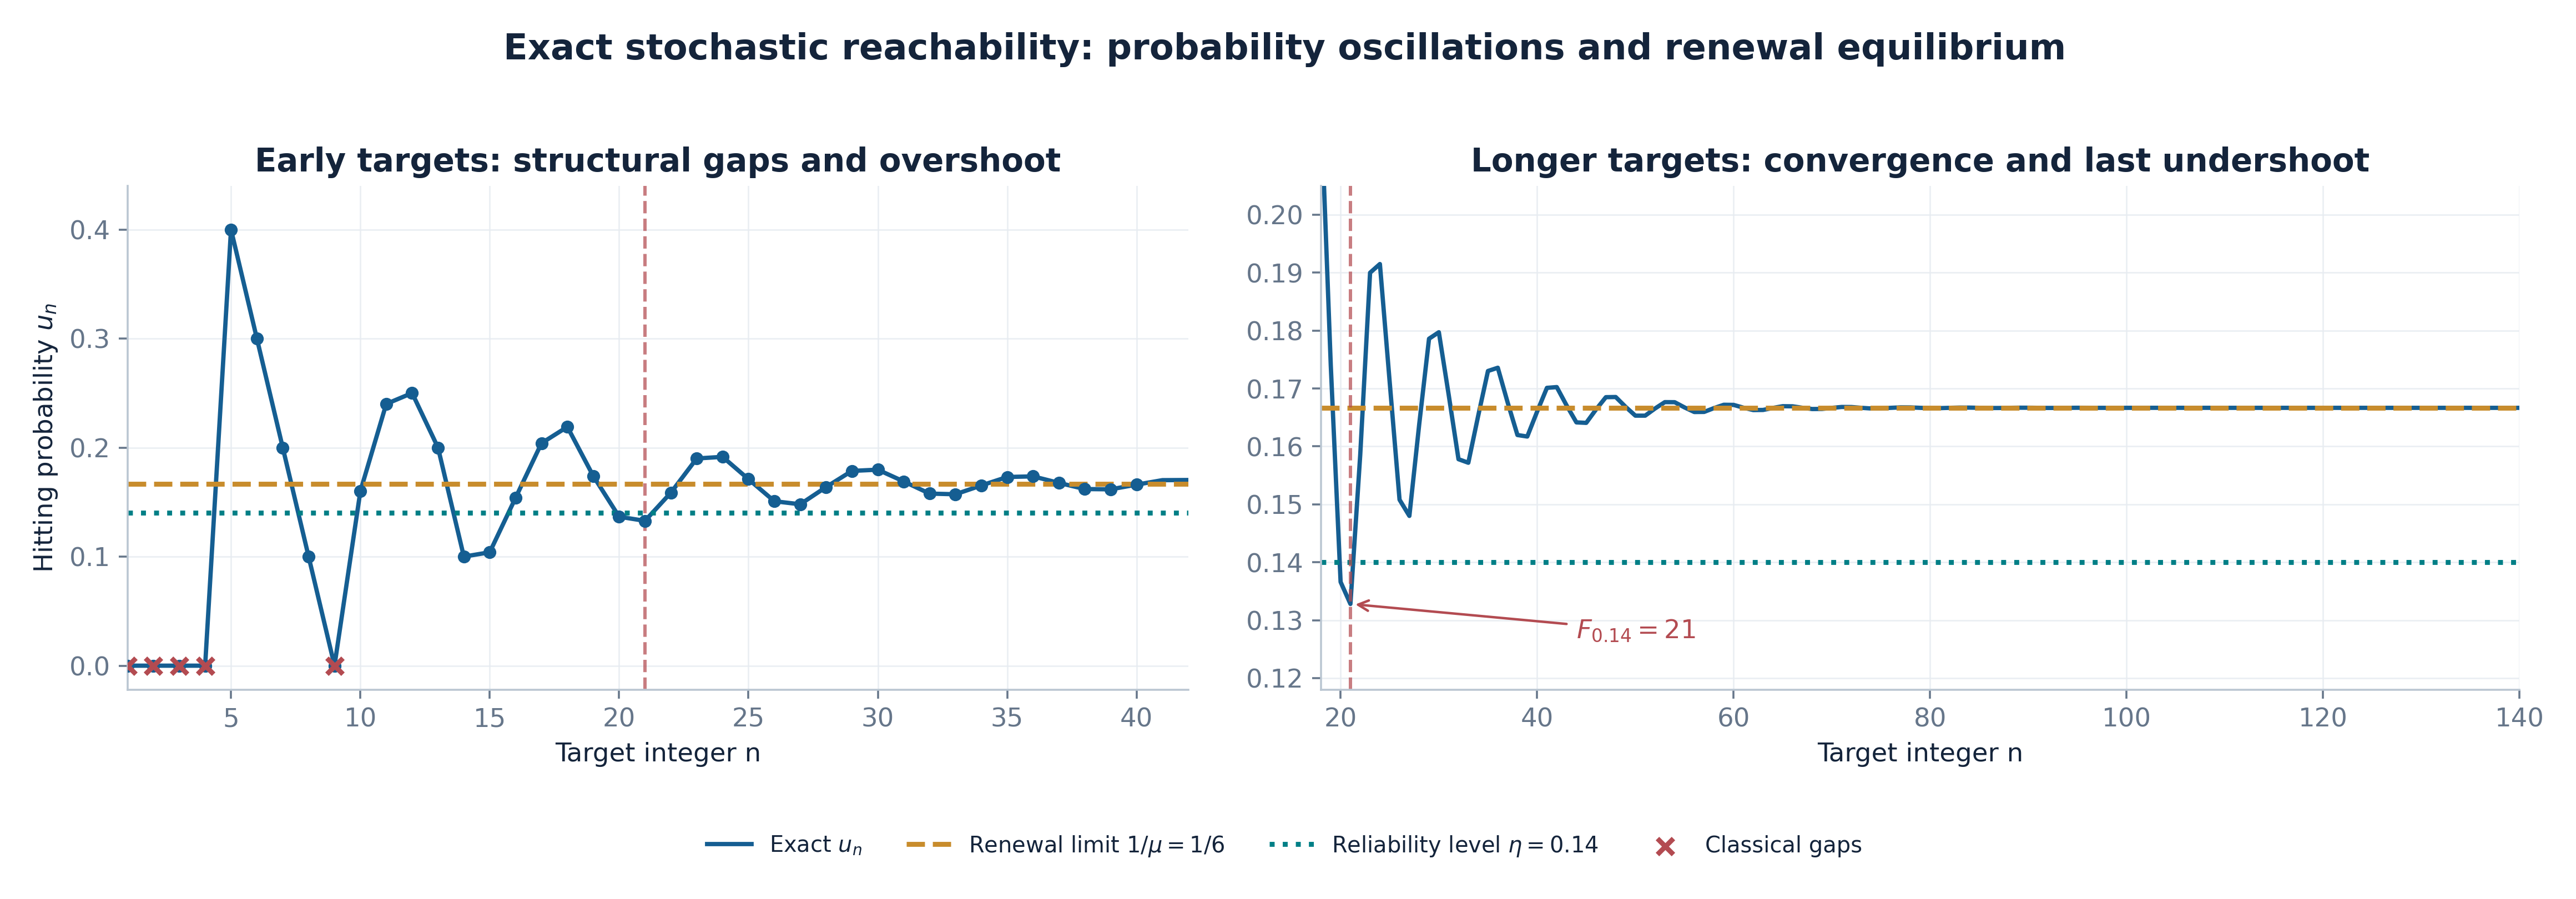

FIGURE: Fig05_independent_path_validation


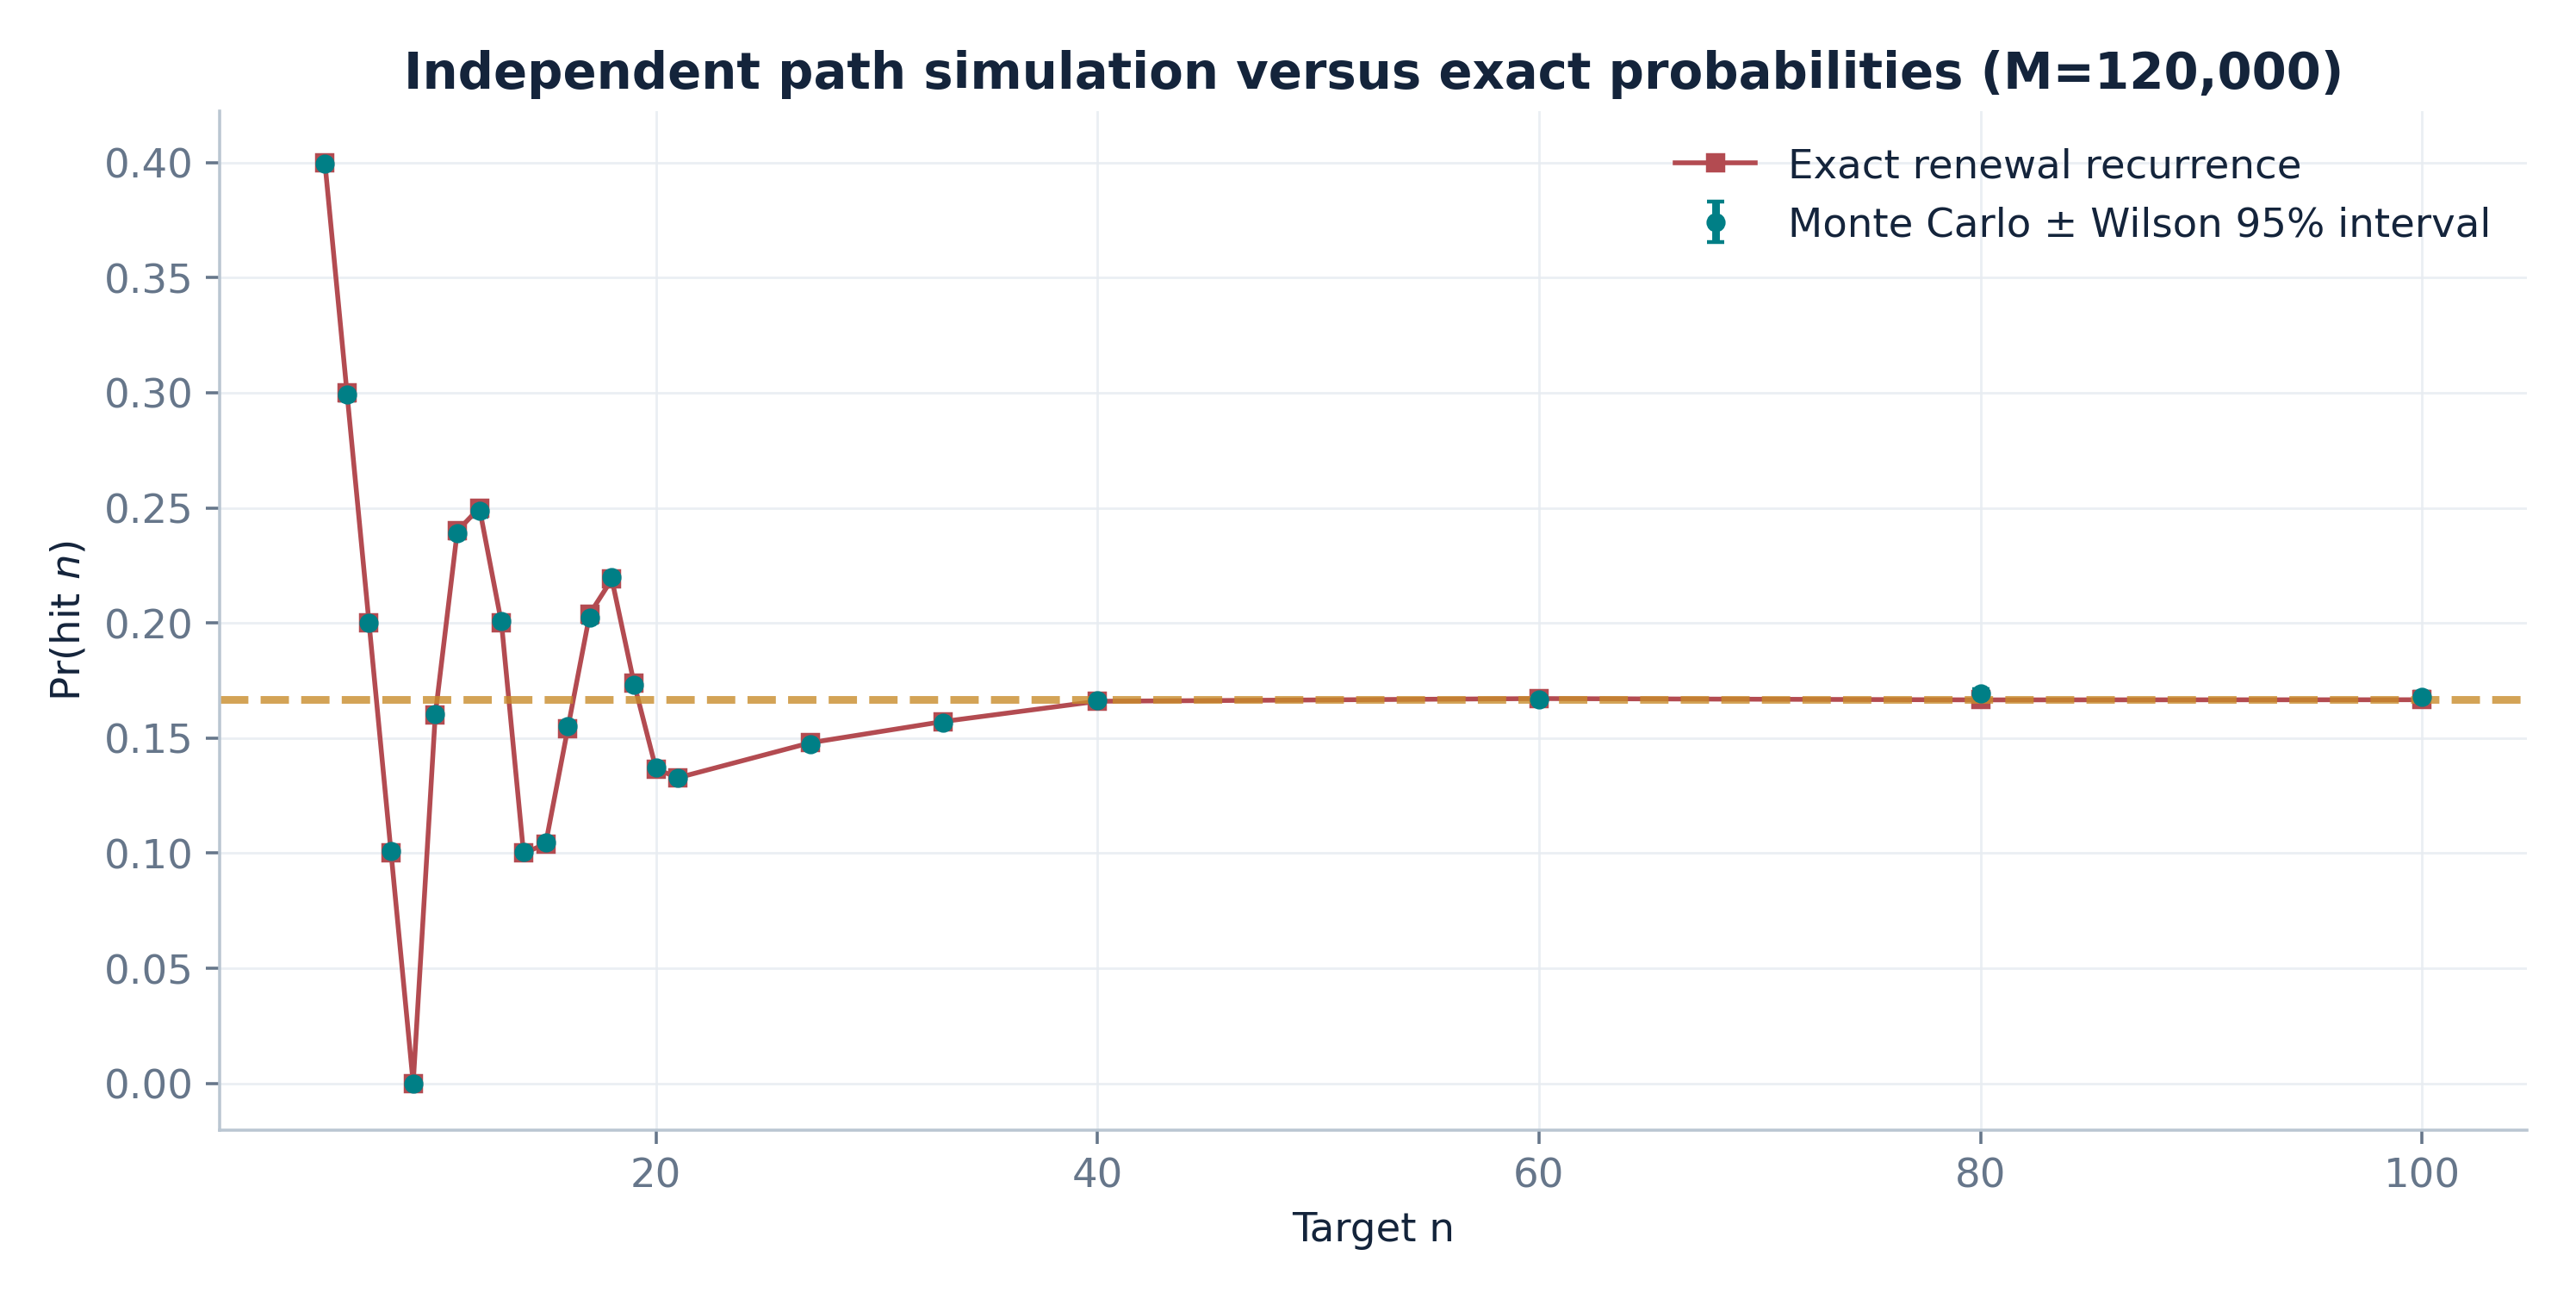

FIGURE: Fig07_two_parameter_sensitivity


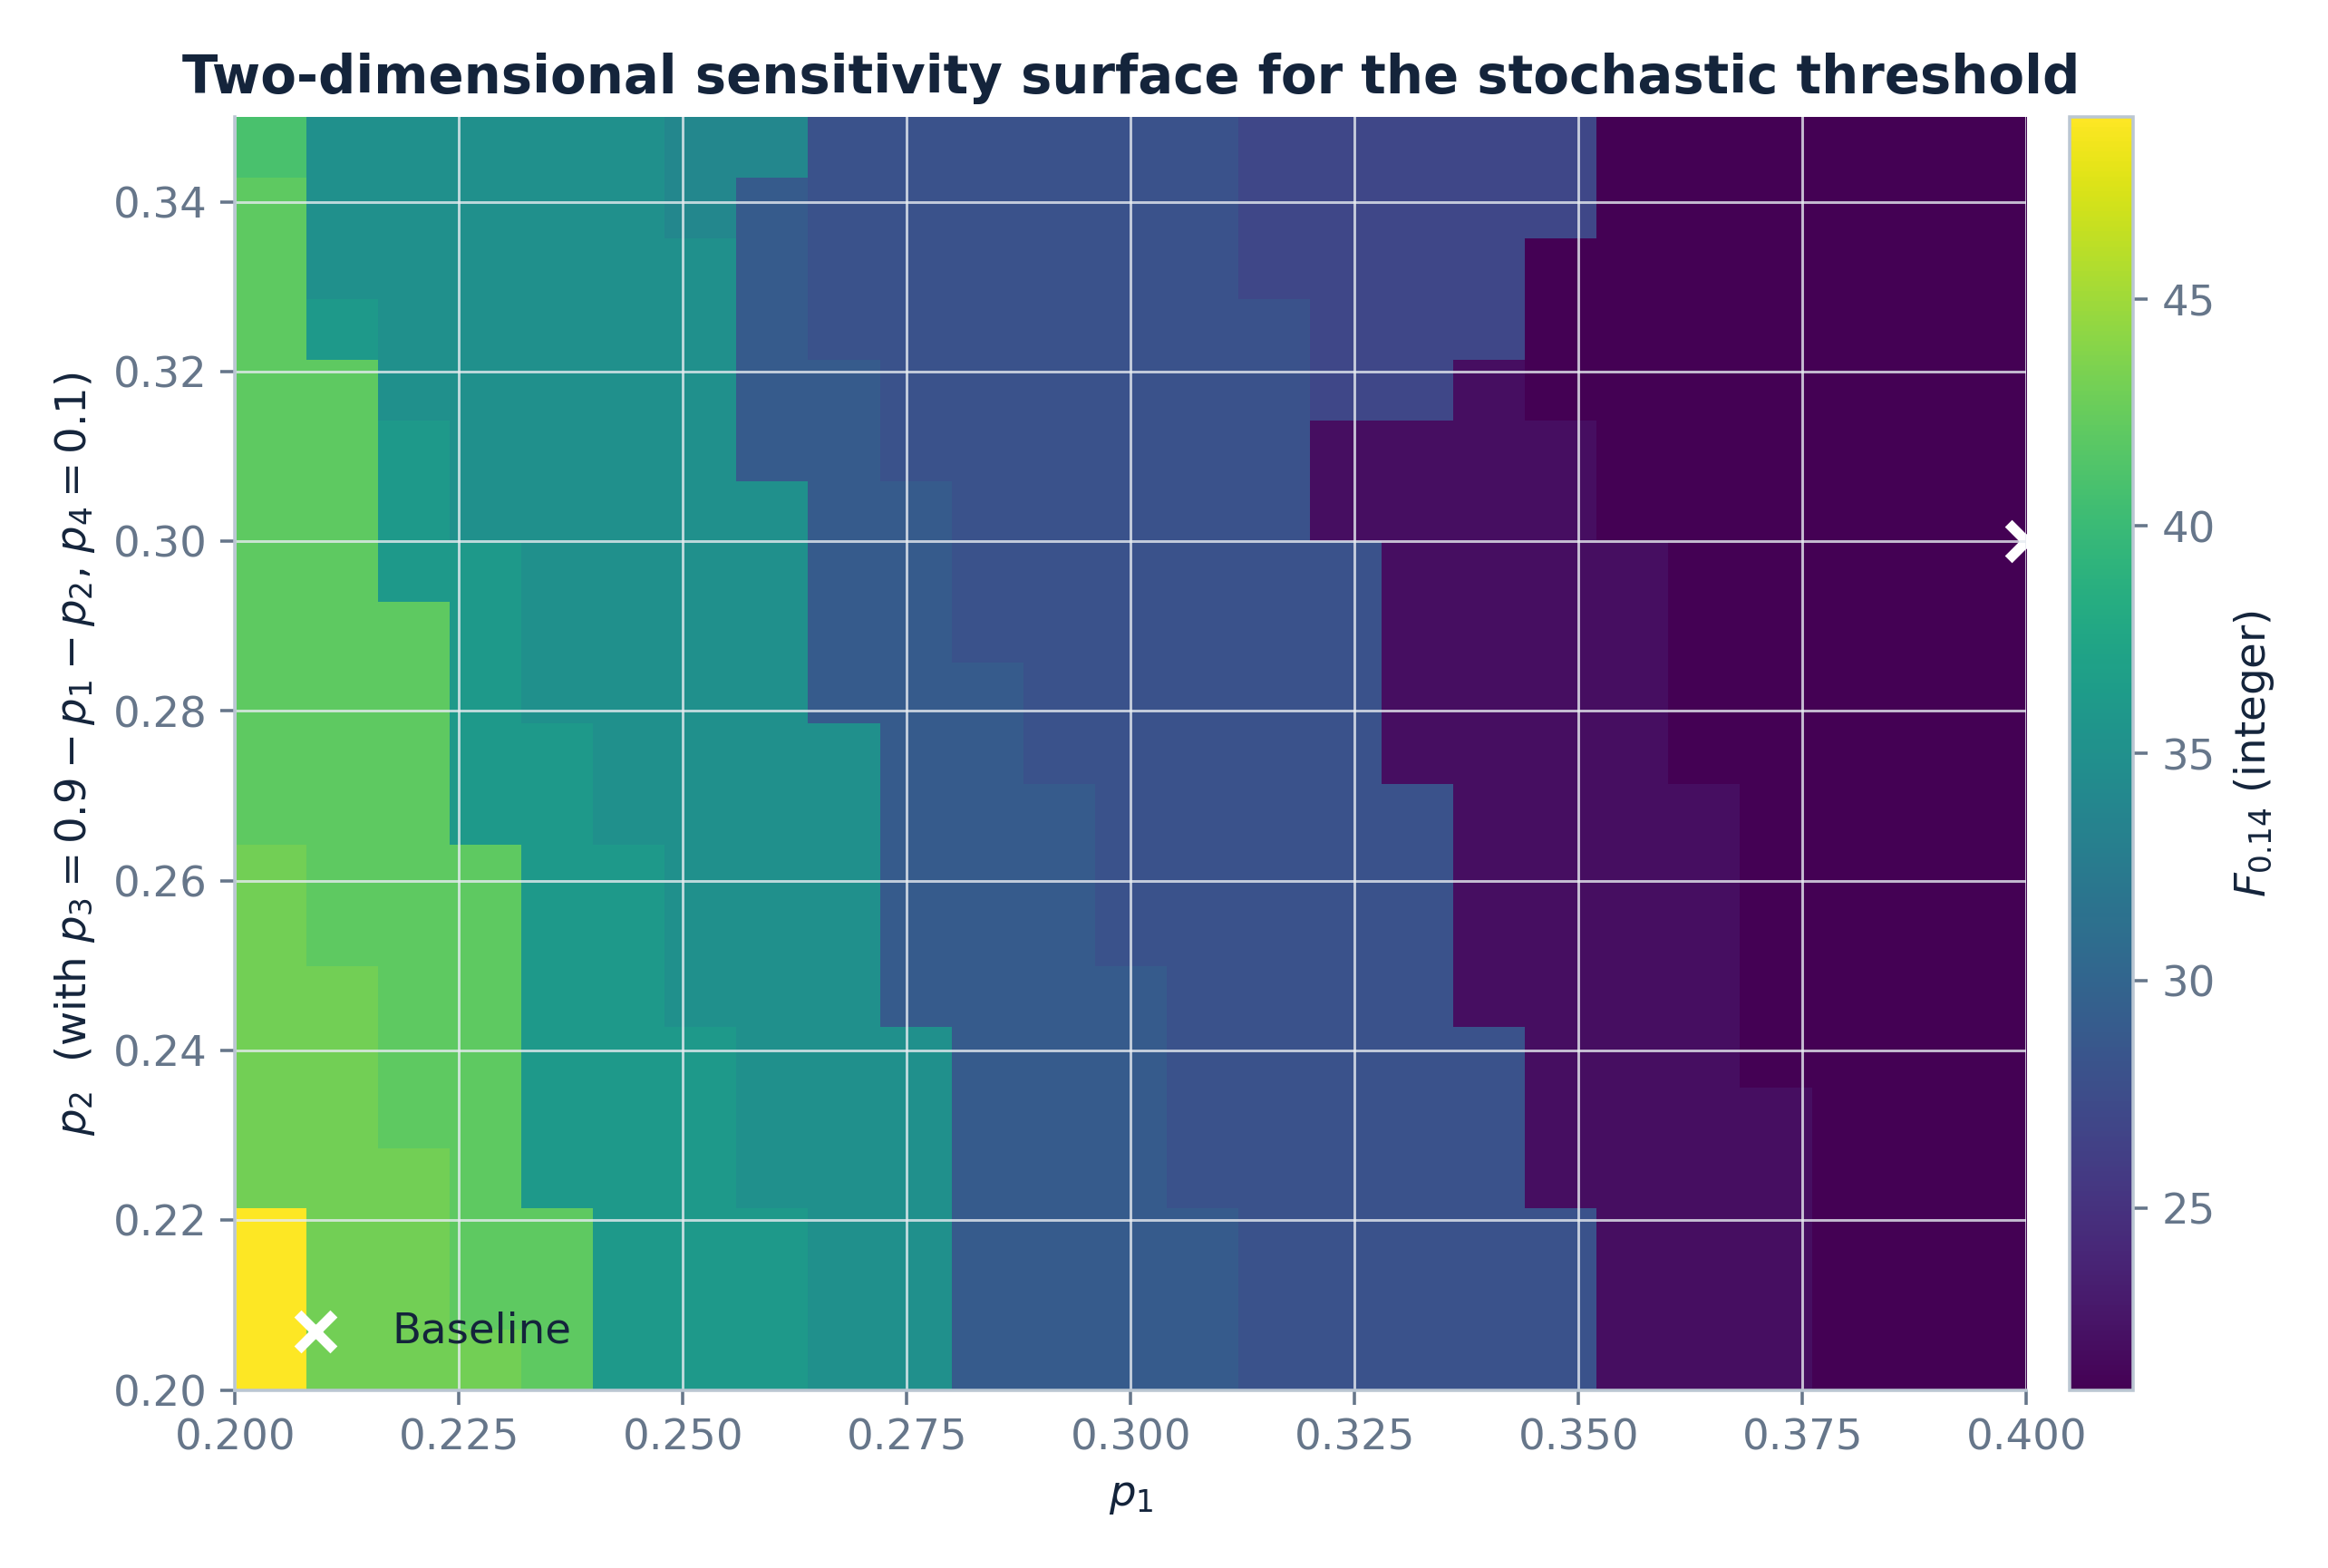

FIGURE: Fig08_delta_method_normality


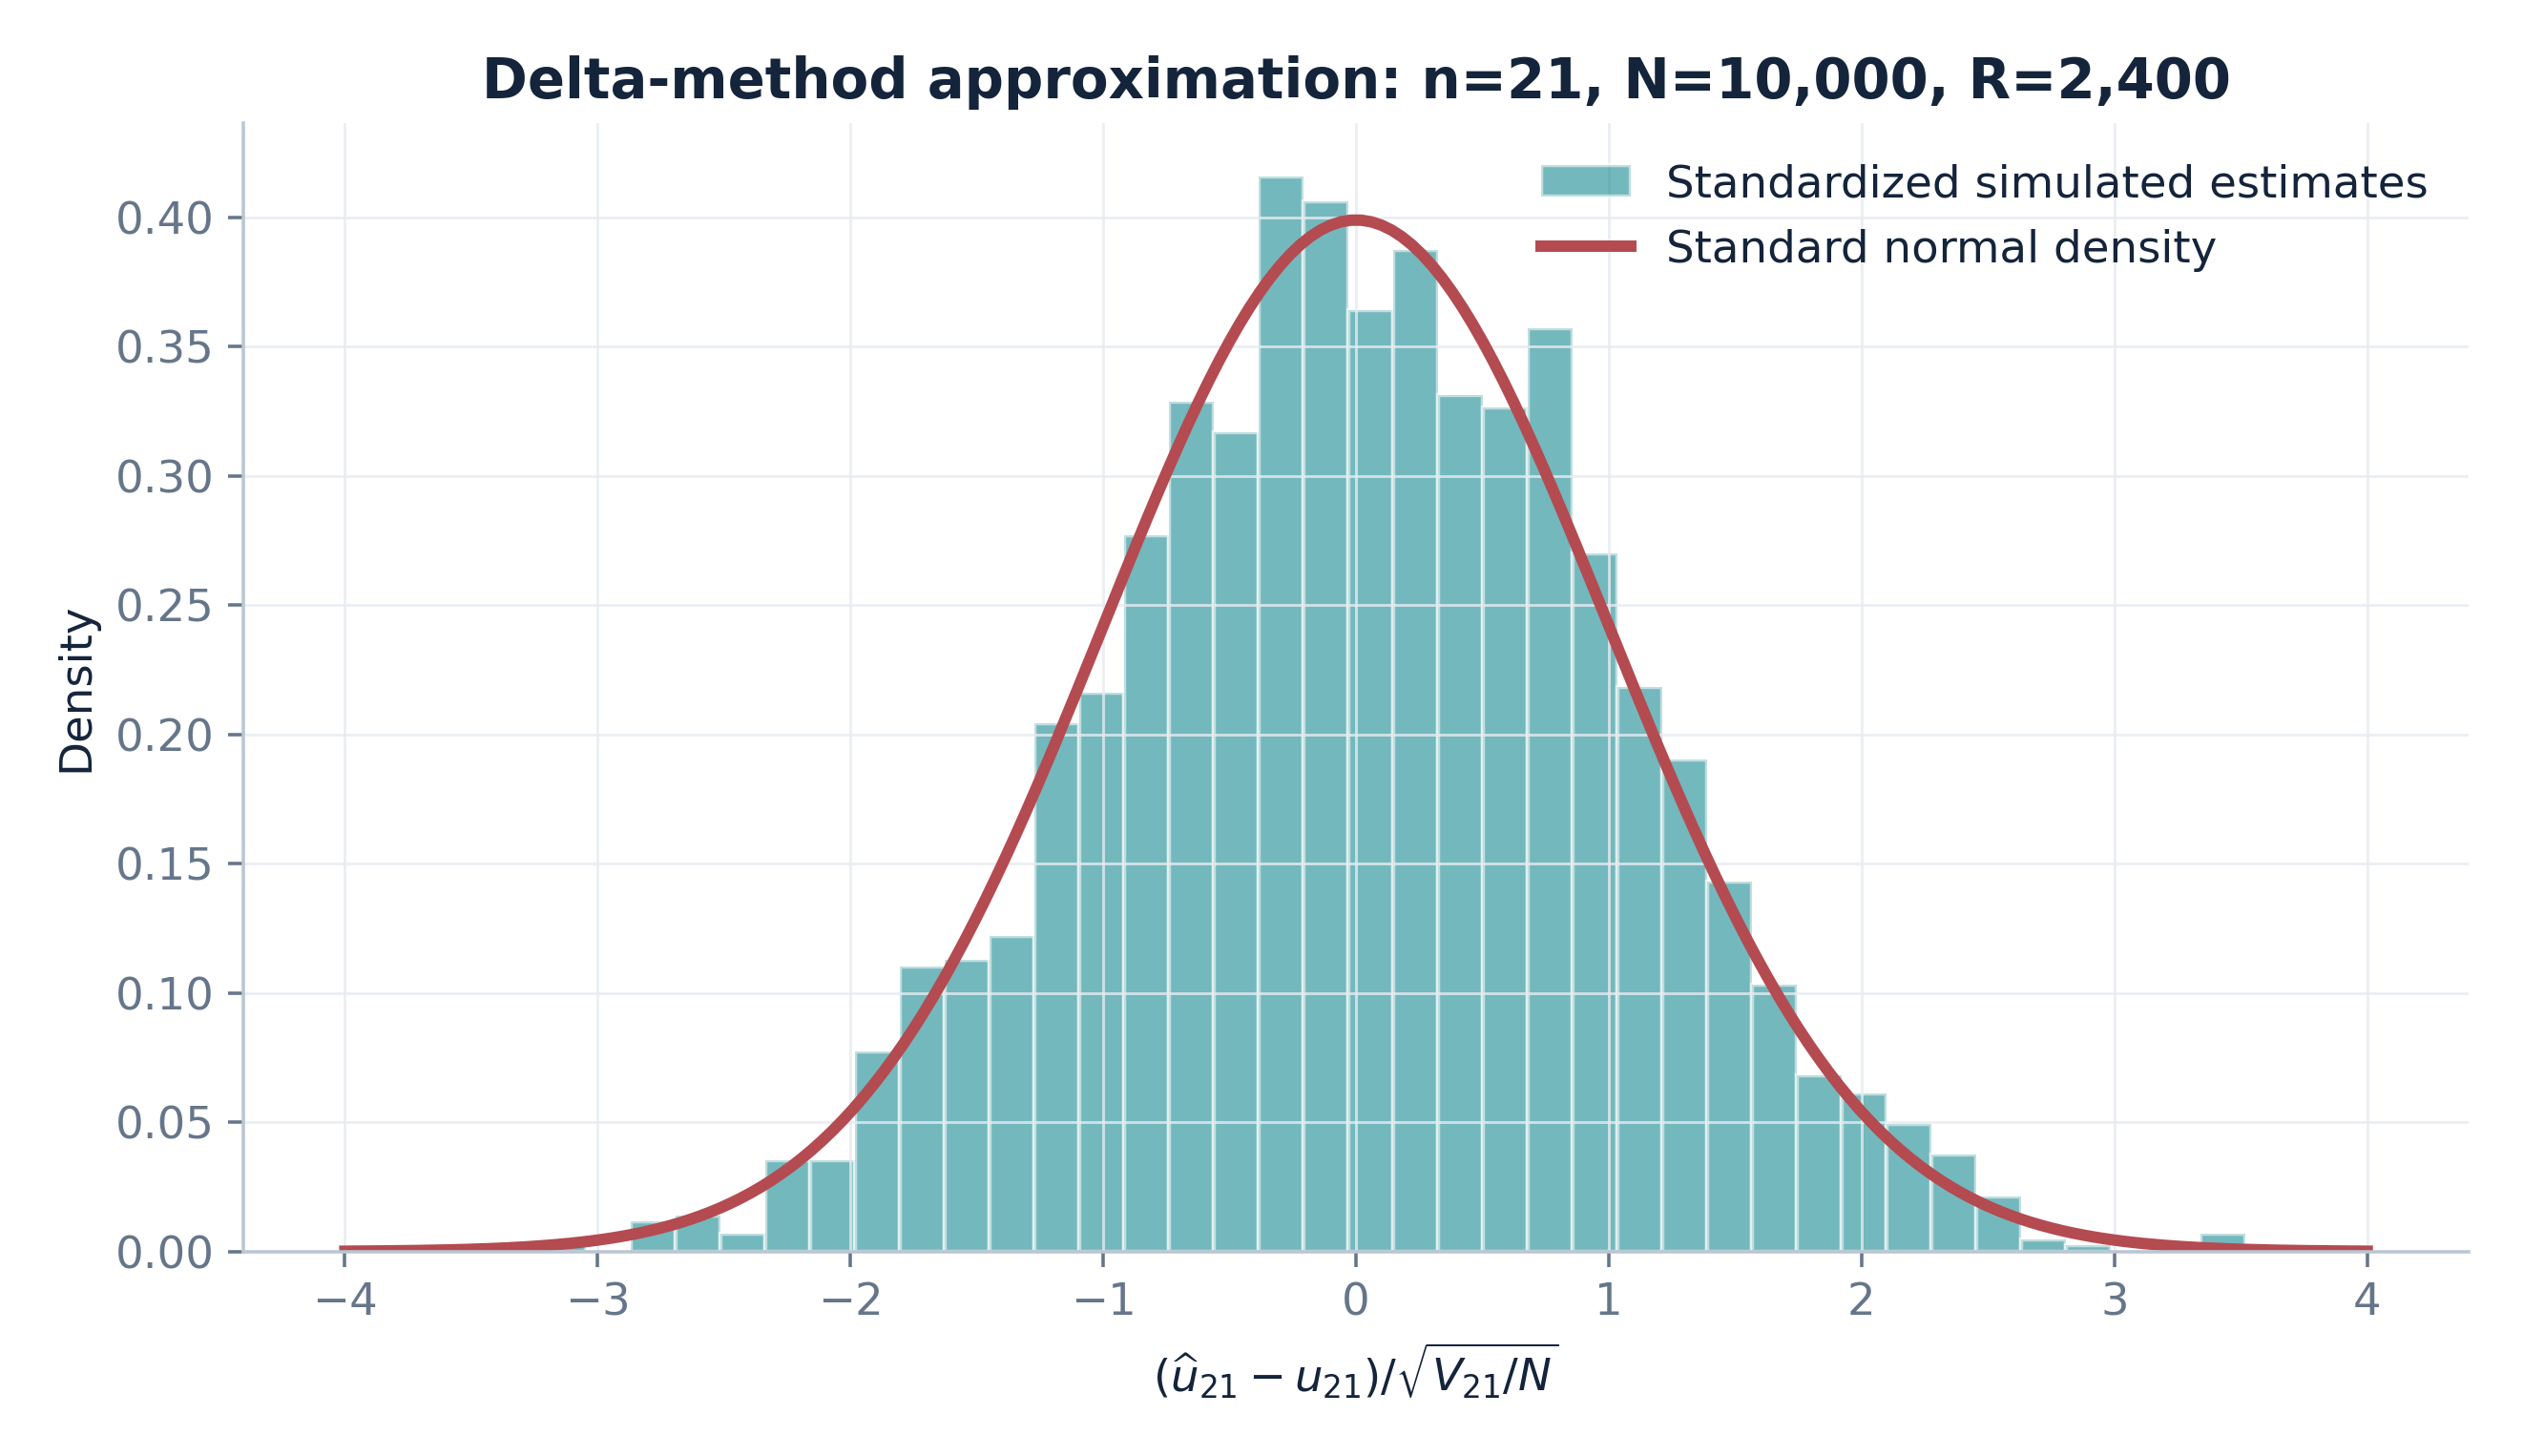

FIGURE: Fig11_finite_sample_confidence_bounds


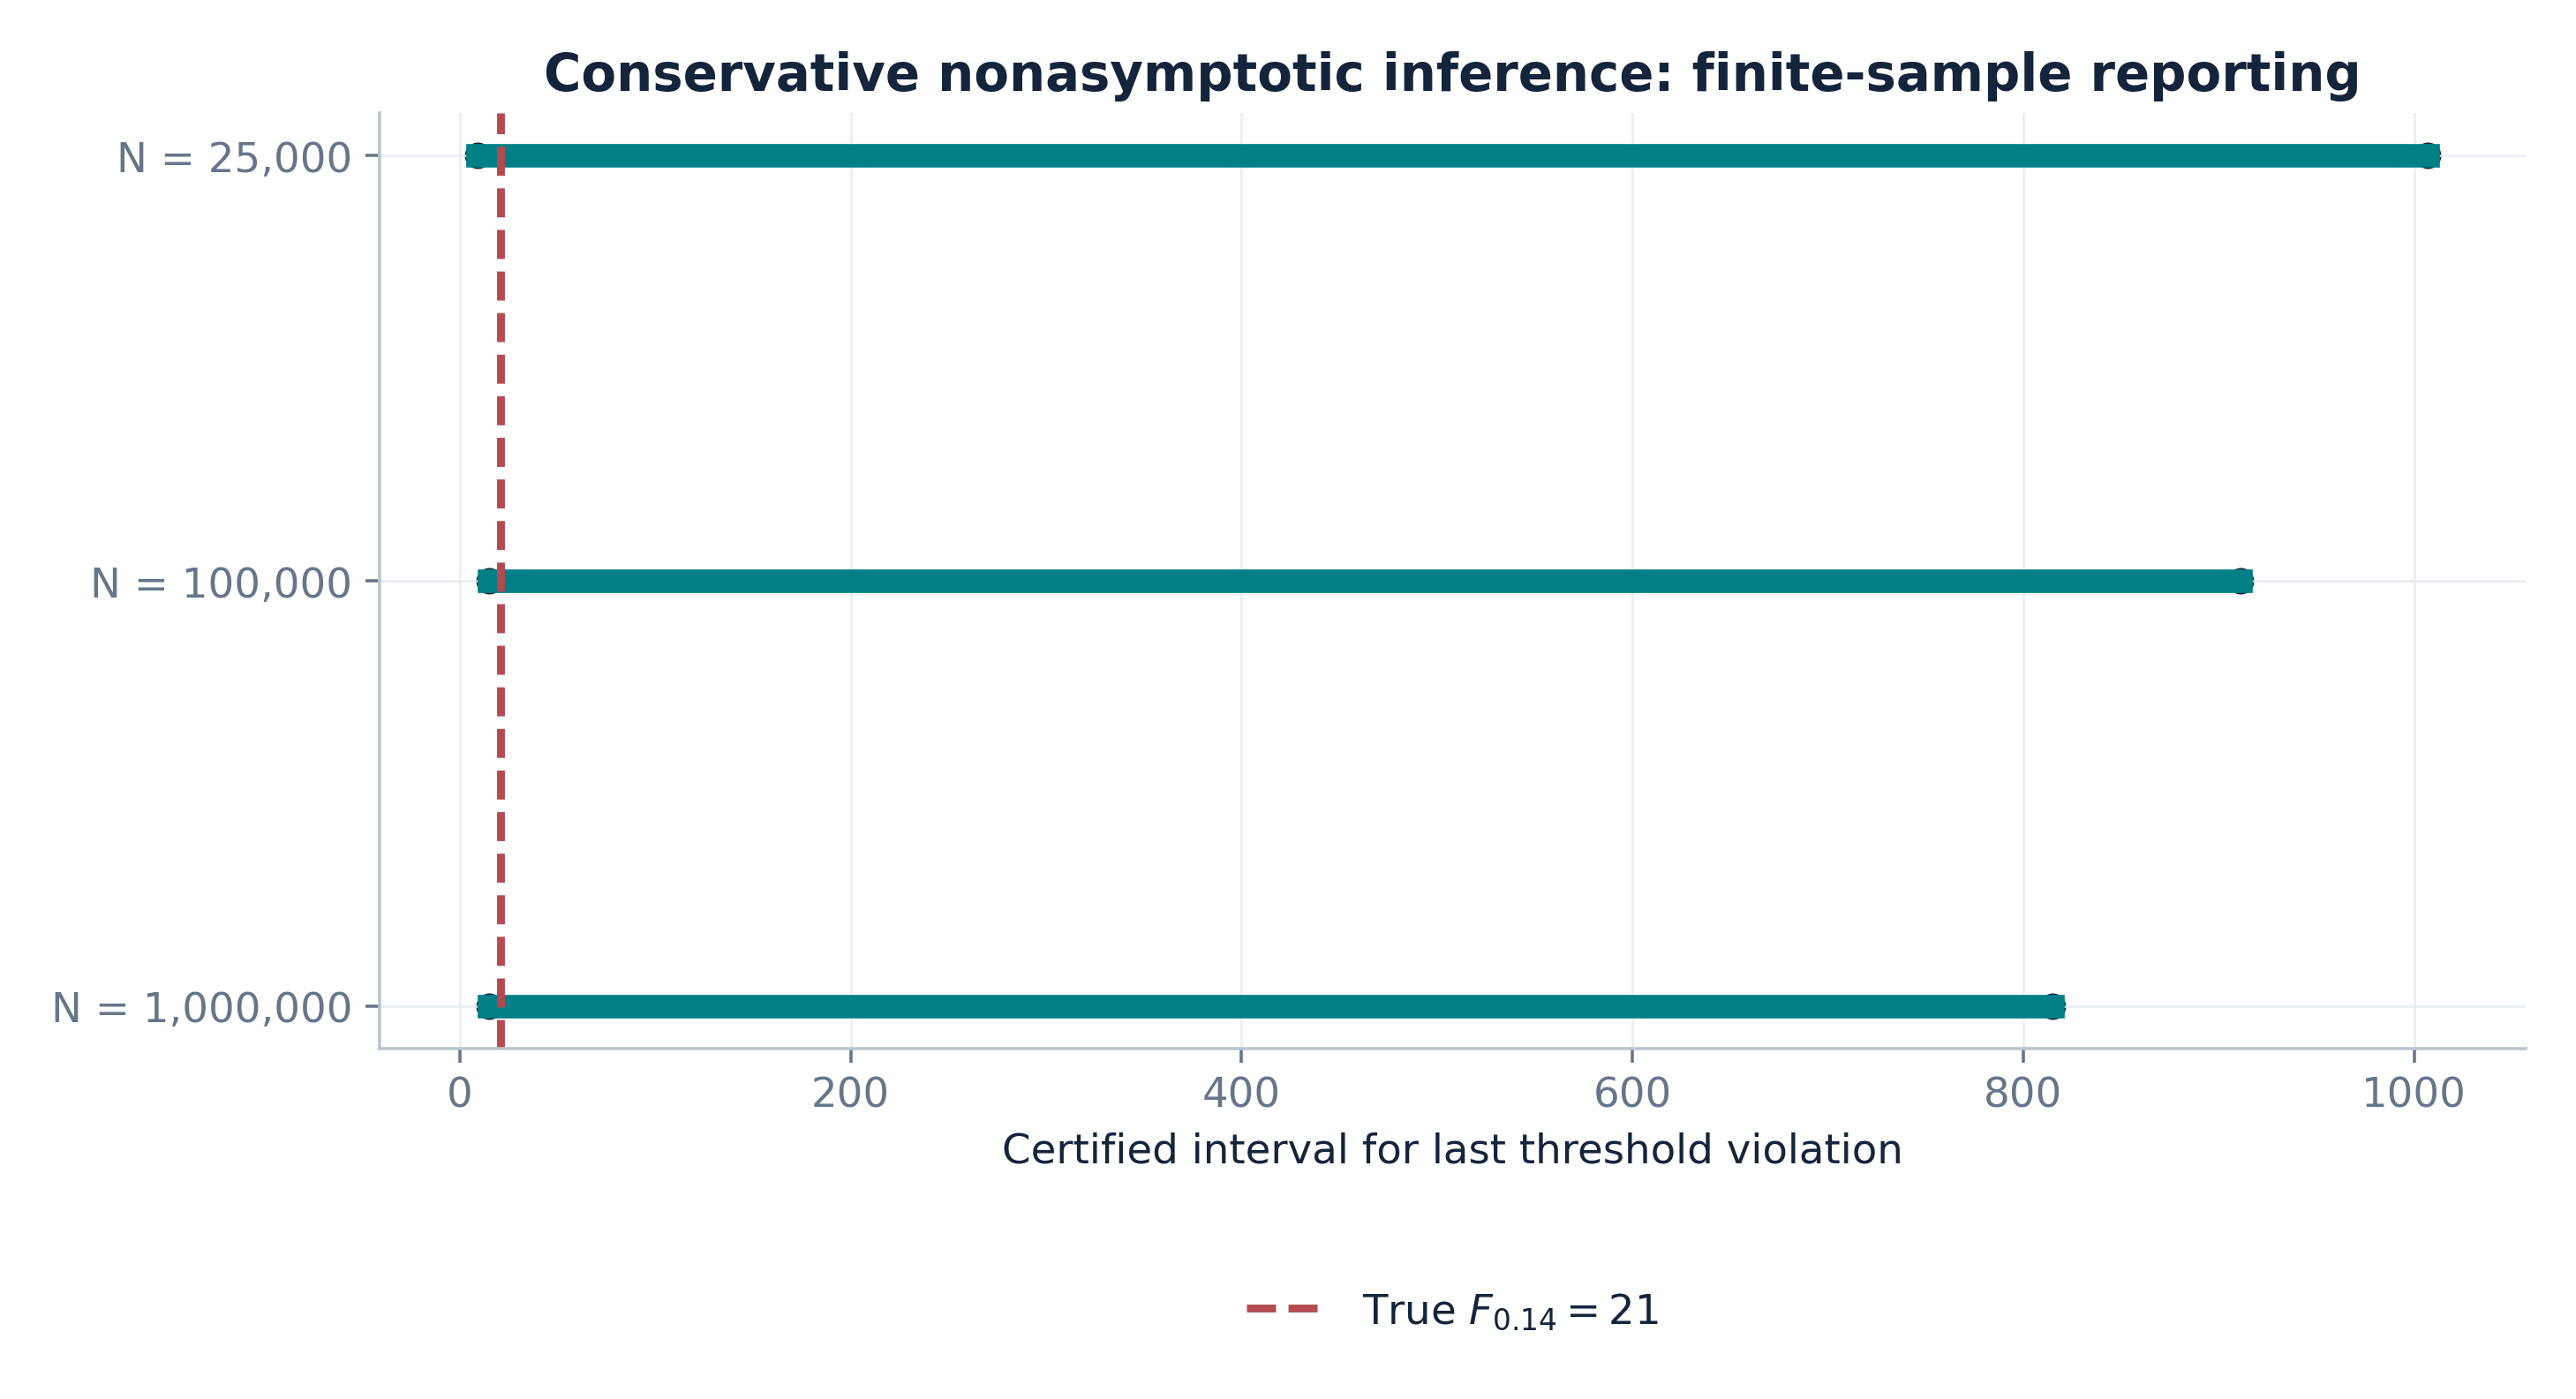

In [ ]:
import pandas as pd
from IPython.display import display, Image
for name in ['01_exact_thresholds', '06_pathwise_monte_carlo',
             '09_delta_method_sampling_properties',
             '10_threshold_estimation_performance',
             '11_rigorous_confidence_interval_examples',
             '14_selective_reporting_operating_characteristics']:
    print('\nTABLE:',name)
    tab=pd.read_csv(output_dir/'tables'/f'{name}.csv')
    display(tab.head(24))
for fig in ['Fig01_exact_renewal_probabilities','Fig05_independent_path_validation',
            'Fig07_two_parameter_sensitivity','Fig08_delta_method_normality',
            'Fig11_finite_sample_confidence_bounds']:
    print('FIGURE:',fig)
    display(Image(filename=str(output_dir/'figures'/f'{fig}.png'),width=850))

## 4. Download the complete research archive

The archive includes **every** full-run CSV, LaTeX table, raster/vector figure, diagnostic certificate, source code, and machine-readable audit manifest. Re-run with another seed to obtain an independent simulation replication, then return the ZIP for manuscript integration.

**Validation caveat:** For a stringent confidence theorem, a very broad certified interval must be reported as broad. The exploratory multinomial bootstrap is not a substitute for its nonasymptotic coverage guarantee.

In [ ]:
from zipfile import ZipFile
with ZipFile(output_zip) as z:
    assert z.testzip() is None
    print('Archive integrity PASS —',len(z.namelist()),'files')
try:
    from google.colab import files
    files.download(str(output_zip))
except ImportError:
    print('Not a Colab runtime; obtain the ZIP at:',output_zip)

Archive integrity PASS — 83 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Supplementary experiment: critical-boundary limit and local alternatives
This notebook has one self-contained executable cell. You may run it independently or copy that cell to the end of the previous Stochastic Frobenius Colab notebook. It writes a second ZIP archive and never edits the old results.

Experiment: a=(5,6,7,8), p0=(0.4,0.3,0.2,0.1), eta=83/625.

The full profile has 6 sample sizes × 7 local shifts × 3,000 replications, plus 3 nested-bootstrap sample sizes × 240 data sets × 450 resamples. The output includes seven new figures and twelve CSV tables (with compact LaTeX tables for presentation).

In [ ]:
# ============================================================================
#  COLAB CELL -- STOCHASTIC FROBENIUS BOUNDARY EXPERIMENT (V2)
# Paste into ONE NEW CELL after the existing notebook (or run standalone).
# The old 13 figures, 19 tables, and old ZIP are not read or overwritten.
# Requires: numpy, scipy, pandas, matplotlib (default Colab installation).
# ============================================================================
import sys, os, json, math, hashlib, platform, zipfile, warnings
from pathlib import Path
from datetime import datetime, timezone
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm

# ------------------------- EDIT ONLY THIS BLOCK -----------------------------
V2_PROFILE = 'full'           # 'quick' first, 'full' for manuscript results
V2_SEED = 2026102302         # independent of all seeds in previous experiment
V2_AUTO_DOWNLOAD = True     # True downloads the SECOND ZIP in Google Colab
V2_SAVE_RAW_REPLICATIONS = True
V2_OUTPUT_ROOT = Path('/content') if 'google.colab' in sys.modules else Path.cwd()
# ---------------------------------------------------------------------------

V2_A = (5, 6, 7, 8)
V2_P0 = np.array([.4, .3, .2, .1], dtype=float)
V2_ETA = 83 / 625
V2_N_STAR, V2_R_STAR = 21, 15
V2_OUT_NAME = 'stochastic_frobenius_boundary_extension_v2'
V2_COLOR = {'ink':'#182A41', 'blue':'#1C6496', 'teal':'#008986',
            'red':'#BC4D51', 'gold':'#B7862E', 'gray':'#647589'}


def v2_style():
    plt.rcParams.update({
        'font.family':'DejaVu Sans', 'font.size':10.4, 'axes.titlesize':12.3,
        'axes.titleweight':'bold', 'axes.labelsize':10.5,
        'axes.spines.top':False, 'axes.spines.right':False,
        'axes.grid':True, 'grid.alpha':.36, 'grid.color':'#CCD7E0',
        'grid.linewidth':.65, 'legend.frameon':False,
        'pdf.fonttype':42, 'ps.fonttype':42,
        'figure.facecolor':'white', 'savefig.facecolor':'white',
        'axes.labelcolor':V2_COLOR['ink'], 'text.color':V2_COLOR['ink']})


def v2_save(fig, name, root):
    for ext in ('png','pdf','svg'):
        fig.savefig(root/'figures'/f'{name}.{ext}', dpi=320,
                    bbox_inches='tight', pad_inches=.17)
    plt.close(fig)


def v2_table(df, name, root, caption, label, tex=True):
    df.to_csv(root/'tables'/f'{name}.csv', index=False, float_format='%.12g')
    if tex:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', FutureWarning)
            latex = df.to_latex(index=False, escape=True, float_format=lambda x:f'{x:.5g}',
                       caption=caption, label=label, position='tbp')
        (root/'tables'/f'{name}.tex').write_text(latex, encoding='utf-8')


def v2_renewal_vector(prob, max_n=75):
    """Vectorized renewal recurrence; each row of prob is a probability law."""
    prob=np.asarray(prob,dtype=float)
    if prob.ndim==1: prob=prob[None,:]
    if prob.shape[1]!=4 or np.any(prob < -1e-13):
        raise ValueError('Expected R x 4 probability matrix')
    if not np.allclose(prob.sum(axis=1),1.0,rtol=0,atol=5e-13):
        raise ValueError('Probability vectors do not sum to one.')
    u=np.zeros((len(prob),max_n+1),dtype=float)
    u[:,0]=1.0
    for n in range(1,max_n+1):
        for j,a in enumerate(V2_A):
            if n>=a: u[:,n]+=prob[:,j]*u[:,n-a]
    return u


def v2_u21_polynomial(prob):
    """Independent exact-form polynomial (numerically evaluated)."""
    pp=np.asarray(prob,dtype=float)
    x,y,z,w=pp[...,0],pp[...,1],pp[...,2],pp[...,3]
    return z**3+3*x*w**2+4*x**3*y+6*y*z*w


def v2_exact_from_counts(count_row, n):
    """Rare float tie-break, computed in arbitrary-precision rationals."""
    c=tuple(int(t) for t in count_row)
    N=sum(c)
    p=tuple(Fraction(t,N) for t in c)
    u=[Fraction(1)]+[Fraction(0)]*n
    for k in range(1,n+1):
        u[k]=sum((p[j]*u[k-a] for j,a in enumerate(V2_A) if k>=a),Fraction(0))
    return u[n] < Fraction(83,625)


def v2_classify_counts(counts, max_n=75):
    """Actual plug-in F, not merely sign(u_21-eta); safe-block certified.

    Exact rational comparisons resolve rare grid equalities at eta.
    Uses sample counts to reconstruct fitted probabilities.
    """
    counts=np.asarray(counts,dtype=np.int64)
    if counts.ndim==1: counts=counts[None,:]
    N=counts.sum(axis=1)
    p=counts/N[:,None]
    u=v2_renewal_vector(p,max_n)
    unsafe=u[:,1:] < V2_ETA
    close=np.argwhere(np.abs(u[:,1:]-V2_ETA)<=3e-13)
    for i,zero_idx in close:
        unsafe[i,zero_idx]=v2_exact_from_counts(counts[i],int(zero_idx)+1)
    bad=np.concatenate([np.zeros((len(p),1),dtype=bool),unsafe],axis=1)
    block_bad=np.zeros((len(p),max_n-8+1),dtype=np.int8)
    for r in range(8):
        block_bad += bad[:,1+r:max_n-8+2+r].astype(np.int8)
    if not np.all(np.any(block_bad==0,axis=1)):
        raise RuntimeError('Some fitted laws lack a safe 8-block by max_n. Raise max_n.')
    last=np.where(unsafe,np.arange(1,max_n+1),0).max(axis=1)
    # polynomial-versus-recursion is an independent implementation check
    assert np.max(abs(u[:,21]-v2_u21_polynomial(p)))<4e-14
    return last,u[:,21],np.sum(close[:,1]==20) if len(close) else 0


def v2_wilson(k,n,level=.95):
    z=norm.ppf((1+level)/2)
    x=k/n; d=1+z*z/n
    cen=(x+z*z/(2*n))/d
    rad=z/d*np.sqrt(x*(1-x)/n+z*z/(4*n*n))
    return max(0,cen-rad),min(1,cen+rad)


def v2_exact_fractions():
    p=tuple(map(Fraction,['0.4','0.3','0.2','0.1']))
    eta=Fraction(83,625)
    u=[Fraction(1)]+[Fraction(0)]*90
    for n in range(1,len(u)):
        u[n]=sum((p[j]*u[n-a] for j,a in enumerate(V2_A) if n>=a), Fraction(0))
    assert u[21] == eta
    assert max(n for n in range(1,90) if u[n]<eta) == 15
    assert min(u[22:30]) == Fraction(37,250)
    # verify no previous index n<21 is equal to the critical eta
    assert all(u[n]!=eta for n in range(1,21))
    # direct derivative from polynomial with p4=1-p1-p2-p3
    x,y,z,w=V2_P0
    # Differentiate u21 = z^3 + 3*x*w^2 + 4*x^3*y + 6*y*z*w,
    # imposing w=1-x-y-z BEFORE differentiation.
    grad=np.array([3*w*w+12*x*x*y-6*x*w-6*y*z,
                   4*x**3+6*z*w-6*x*w-6*y*z,
                   3*z*z+6*y*w-6*y*z-6*x*w],dtype=float)
    g_ref=np.array([3/500,-28/125,-3/10],dtype=float)
    assert np.allclose(grad,g_ref,rtol=0,atol=1e-13),(grad,g_ref)
    cov=np.diag(V2_P0[:3])-np.outer(V2_P0[:3],V2_P0[:3])
    sigma2=float(g_ref@cov@g_ref)
    assert abs(sigma2-54663/3125000)<1e-14
    sigma=np.sqrt(sigma2)
    # local direction h = Sigma*g/sigma; g'h=sigma and h^T Sigma^-1 h=1.
    direction3=cov@g_ref/sigma
    direction4=np.r_[direction3,-direction3.sum()]
    assert abs(g_ref@direction3-sigma)<1e-13
    assert abs(direction4.sum())<1e-14
    # derivative verified independently by centred finite differences
    eps=2e-6
    fd=[]
    for j in range(3):
        d=np.zeros(4); d[j]=eps; d[3]=-eps
        fd.append((v2_u21_polynomial(V2_P0+d)-
                   v2_u21_polynomial(V2_P0-d))/(2*eps))
    assert np.allclose(fd,g_ref,rtol=0,atol=3e-10),(fd,g_ref)
    return u,g_ref,cov,sigma,direction4


def v2_local_p(N,lam,direction4):
    p=V2_P0+float(lam)*direction4/np.sqrt(int(N))
    p[3]=1-sum(p[:3])
    if min(p)<=0:raise RuntimeError(f'Invalid local alternative N={N} lambda={lam}')
    return p


def v2_run(profile=V2_PROFILE,seed=V2_SEED,root=V2_OUTPUT_ROOT):
    if profile not in ('quick','full'): raise ValueError('profile must be quick/full')
    t0=__import__('time').perf_counter()
    import shutil
    out=Path(root)/V2_OUT_NAME
    if out.exists(): shutil.rmtree(out)  # removes ONLY V2 folder
    for sub in ('figures','tables','verification','source'):
        (out/sub).mkdir(parents=True,exist_ok=True)
    v2_style()
    rng=np.random.default_rng(int(seed))
    exact_u,g,cov,sigma,direction=v2_exact_fractions()
    N_GRID=[250,500,1000,2000,5000,10000] if profile=='full' else [500,2000]
    L_GRID=[-2.,-1.,-.5,0.,.5,1.,2.] if profile=='full' else [-1.,0.,1.]
    R=3000 if profile=='full' else 250
    BOOT_N=[500,2000,10000] if profile=='full' else [500]
    OUTER=240 if profile=='full' else 20
    B=450 if profile=='full' else 60
    NMAX=75
    print('V2: exact critical boundary checks passed; running local alternatives.')
    checks=pd.DataFrame([{'parameter':'a','value':'(5,6,7,8)'},
        {'parameter':'p0','value':'(0.4,0.3,0.2,0.1)'},
        {'parameter':'eta','value':'83/625 = 0.1328'},
        {'parameter':'u21','value':str(exact_u[21])},
        {'parameter':'F_eta(p0)','value':'15'},
        {'parameter':'min(u22,...,u29)','value':str(min(exact_u[22:30]))},
        {'parameter':'grad_(p1,p2,p3) u21','value':np.array2string(g,precision=8)},
        {'parameter':'sigma2','value':'54663/3125000'},
        {'parameter':'sigma','value':f'{sigma:.12g}'},
        {'parameter':'h_full(lambda=1)','value':np.array2string(direction,precision=9)},
        {'parameter':'normalization g^T h3 /sigma','value':f'{(g@direction[:3]/sigma):.12g}'}])
    v2_table(checks,'16_critical_boundary_exact_checks',out,
        'Exact critical-model identities and local-parameter normalization',
        'tab:boundary-exact')
    rows=[]; raw=[]; pop=[]
    for N in N_GRID:
        for lam in L_GRID:
            law=v2_local_p(N,lam,direction)
            popU=v2_renewal_vector(law,75)[0]
            # independent finite-block check for population threshold
            p_bad=popU[1:]<V2_ETA
            if lam==0.0: p_bad[20]=False # mathematically exactly equal
            popF=int(np.where(p_bad,np.arange(1,76),0).max())
            assert popF == (21 if lam<0 else 15),(N,lam,popF)
            assert any(np.all(~p_bad[s-1:s+7]) for s in range(1,76-8+1))
            counts=rng.multinomial(N,law,size=R)
            f,uhat,ties=v2_classify_counts(counts,max_n=NMAX)
            T=np.sqrt(N)*(uhat-V2_ETA)/sigma
            n21=int(np.count_nonzero(f==21)); n15=int(np.count_nonzero(f==15))
            other=R-n21-n15
            q=float(norm.cdf(-lam)); lo,hi=v2_wilson(n21,R)
            risk=float(np.mean(f!=popF))
            row=dict(N=N,lambda_standard=lam,R=R,population_F=popF,
                     population_u21=popU[21],population_surplus=popU[21]-V2_ETA,
                     p_hat_F21=n21/R,p_hat_F15=n15/R,p_other=other/R,
                     theory_P_F21=q,wilson_low=lo,wilson_high=hi,
                     MC_minus_theory=n21/R-q,
                     empirical_misclassification=risk,
                     theory_misclassification=norm.cdf(-abs(lam)),
                     T_mean=float(T.mean()),T_sd=float(T.std(ddof=1)),
                     T_theory_mean=lam,near_exact_tiebreaks=ties)
            rows.append(row)
            pop.append(dict(N=N,lambda_standard=lam,
                p1=law[0],p2=law[1],p3=law[2],p4=law[3],
                population_u21=popU[21],population_F=popF))
            if V2_SAVE_RAW_REPLICATIONS:
                raw.append(pd.DataFrame(dict(N=N,lambda_standard=lam,
                    replication=np.arange(1,R+1),c1=counts[:,0],c2=counts[:,1],
                    c3=counts[:,2],c4=counts[:,3],u21_plugin=uhat,
                    plugin_F=f,T_stat=T,population_F=popF)))
    res=pd.DataFrame(rows); population=pd.DataFrame(pop)
    if res.p_other.max()>0.03:
        print('INFO: Finite-N mass outside {15,21} is non-negligible; retained without censoring:', round(float(res.p_other.max()),4))
    v2_table(res,'18_local_alternatives_full_grid',out,
        'Local-alternative Monte Carlo results (pointwise Wilson intervals)',
        'tab:boundary-local-full',tex=False)
    v2_table(population,'24_local_population_truths',out,
        'Exactly specified population alternatives and threshold classifications',
        'tab:boundary-population',tex=False)
    # Compact presentation table: full experimental records remain in CSV.
    compact=res[(res.N.isin([N_GRID[0],N_GRID[-1]])) &
               (res.lambda_standard.isin([-2.,-1.,0.,1.,2.]))][
                 ['N','lambda_standard','population_F','p_hat_F21',
                  'theory_P_F21','p_other','empirical_misclassification']].copy()
    v2_table(compact,'18a_local_alternatives_compact',out,
             'Selected local alternatives: switching, other-mass, and risk',
             'tab:boundary-local-compact')
    if raw:
        v2_table(pd.concat(raw,ignore_index=True),'25_local_replication_level',out,
             'Replication-level local-alternative results','tab:boundary-raw',tex=False)
    critical=res[res.lambda_standard==0].copy()
    critical=critical[['N','R','p_hat_F15','p_hat_F21','p_other',
             'wilson_low','wilson_high','T_mean','T_sd']]
    v2_table(critical,'17_boundary_two_point_convergence',out,
        'Empirical convergence to the nondegenerate two-point boundary law',
        'tab:boundary-two-point')
    risks=res[['N','lambda_standard','population_F',
         'empirical_misclassification','theory_misclassification']].copy()
    v2_table(risks,'19_local_misclassification_risk',out,
        'Misclassification under local alternatives (theoretical curve is Phi(-abs(lambda)))',
        'tab:boundary-local-risk')

    # Figure 14: two-point limit, with individually computed MC Wilson intervals.
    fig,ax=plt.subplots(figsize=(8.0,4.8))
    ax.errorbar(critical.N,critical.p_hat_F21,
        yerr=[critical.p_hat_F21-critical.wilson_low,
              critical.wilson_high-critical.p_hat_F21],
        fmt='o-',capsize=3.0,color=V2_COLOR['red'],label=r'$\Pr(\widehat F_\eta=21)$')
    ax.plot(critical.N,critical.p_hat_F15,'s--',color=V2_COLOR['teal'],
            label=r'$\Pr(\widehat F_\eta=15)$')
    ax.axhline(.5,color=V2_COLOR['ink'],ls=':',lw=1.8,
               label='Theoretical limit: 1/2')
    ax.set(xlabel='Sample size N',ylabel='Empirical probability',ylim=(.38,.62),
           title='Nondegenerate two-point law at the critical distribution')
    ax.set_xscale('log');ax.set_ylim(0.25,0.65);ax.legend(loc='best');v2_save(fig,'Fig14_boundary_two_point_limit',out)

    # Figure 15: local switching probabilities across N with normal limits.
    fig,ax=plt.subplots(figsize=(8.3,5.1))
    xx=np.linspace(-2.15,2.15,250)
    ax.plot(xx,norm.cdf(-xx),'-',lw=2.5,color=V2_COLOR['ink'],
            label=r'Limit $\Phi(-\lambda)$')
    for N,clr,mark in [(N_GRID[0],V2_COLOR['gold'],'o'),
                        (N_GRID[-2] if len(N_GRID)>2 else N_GRID[-1],V2_COLOR['teal'],'s'),
                        (N_GRID[-1],V2_COLOR['blue'],'^')]:
        sel=res[res.N==N]
        ax.errorbar(sel.lambda_standard,sel.p_hat_F21,
          yerr=[sel.p_hat_F21-sel.wilson_low,sel.wilson_high-sel.p_hat_F21],
          color=clr,fmt=mark+'--',capsize=2,ms=5,label=f'N={N:,}')
    ax.set(xlabel=r'Local displacement $\lambda$',ylabel=r'$\Pr(\widehat F_\eta=21)$',
       title='Local-alternative transition across the reliability surface',ylim=(-.03,1.03))
    ax.legend();v2_save(fig,'Fig15_local_switching_probabilities',out)

    # Figure 16: misclassification risk.  The true threshold flips at lambda=0.
    fig,ax=plt.subplots(figsize=(8.3,4.9))
    ax.plot(xx,norm.cdf(-np.abs(xx)),lw=2.5,color=V2_COLOR['ink'],
            label=r'Local-asymptotic risk $\Phi(-|\lambda|)$')
    for N,clr in [(N_GRID[0],V2_COLOR['gold']),(N_GRID[-1],V2_COLOR['blue'])]:
        sel=res[res.N==N]
        ax.plot(sel.lambda_standard,sel.empirical_misclassification,'o--',
                label=f'N={N:,}',color=clr)
    ax.set(xlabel=r'Local displacement $\lambda$',ylabel='Misclassification probability',
       title='Threshold identification has positive local-asymptotic risk',ylim=(-.02,.75))
    ax.legend();v2_save(fig,'Fig16_local_misclassification_risk',out)

    # Figure 17: sample distribution of the smooth statistic (not threshold).
    if raw:
        raw_all=pd.concat(raw,ignore_index=True)
        fig,ax=plt.subplots(1,2,figsize=(11.5,4.4))
        grid=np.linspace(-3.5,3.5,220)
        for N,clr in [(N_GRID[0],V2_COLOR['gold']),(N_GRID[-1],V2_COLOR['blue'])]:
            x=raw_all.loc[(raw_all.N==N)&(raw_all.lambda_standard==0),'T_stat'].to_numpy()
            ax[0].hist(x,bins=45,density=True,histtype='step',lw=1.65,
                       color=clr,label=f'N={N:,}')
        ax[0].plot(grid,norm.pdf(grid),lw=2.3,color=V2_COLOR['ink'],label='N(0,1) density')
        ax[0].set(xlabel=r'$T_N=\sqrt{N}(\widehat u_{21}-\eta)/\sigma_\star$',
                  ylabel='Density',title='Gaussian limit for the smooth contrast')
        ax[0].legend()
        x=raw_all.loc[(raw_all.N==N_GRID[-1])&
                (raw_all.lambda_standard==0),'T_stat'].to_numpy()
        xp=np.sort(x); theoretical=norm.ppf((np.arange(1,len(x)+1)-.5)/len(x))
        ax[1].plot(theoretical,xp,'.',ms=2,alpha=.65,color=V2_COLOR['teal'])
        ax[1].plot([-3.6,3.6],[-3.6,3.6],'--',color=V2_COLOR['ink'])
        ax[1].set(xlabel='Standard-normal theoretical quantiles',
                  ylabel='Observed statistic quantiles',title=f'Normal Q--Q, N={N_GRID[-1]:,}')
        v2_save(fig,'Fig17_smooth_CLT_vs_nonsmooth_threshold',out)

    # Figure 20: population boundary geometry, not a duplicate of old surfaces.
    Ngeo=2000; lgeo=np.linspace(-2.8,2.8,221)
    gp=np.vstack([v2_local_p(Ngeo,lam,direction) for lam in lgeo])
    gu=v2_renewal_vector(gp,75)
    fgeo=np.where(gu[:,21]<V2_ETA,21,15) # exact equality forced safe
    fgeo[np.abs(lgeo)<1e-14]=15
    fig,(ax1,ax2)=plt.subplots(2,1,figsize=(8.6,6.2),sharex=True,
                               gridspec_kw={'height_ratios':[1.6,1]})
    ax1.plot(lgeo,gu[:,21]-V2_ETA,color=V2_COLOR['blue'],lw=2.2)
    ax1.axhline(0,ls=':',color=V2_COLOR['red']);ax1.axvline(0,ls=':',color=V2_COLOR['gray'])
    ax1.set(ylabel=r'$u_{21}(p_{N,\lambda})-\eta$',
            title='Analytic local crossing of the critical reliability surface')
    ax2.step(lgeo,fgeo,where='mid',color=V2_COLOR['teal'],lw=2.2)
    ax2.set(xlabel=r'Standardized population displacement $\lambda$',
            ylabel=r'$F_\eta(p_{N,\lambda})$',yticks=[15,21],ylim=(13.8,22.2))
    v2_save(fig,'Fig20_exact_local_boundary_geometry',out)

    # PARAMETRIC BOOTSTRAP: at p0, conditional switching probability does
    # not converge to 1/2.  Conditional law approaches random Phi(-T_obs),
    # which is asymptotically Uniform(0,1) across independent data sets.
    boot_rows=[]; boot_repl=[]
    print('V2: local-alternative analysis completed; running boundary bootstrap.')
    for N in BOOT_N:
        outer_counts=rng.multinomial(N,V2_P0,size=OUTER)
        outerF,outerU,_=v2_classify_counts(outer_counts,NMAX)
        for b in range(OUTER):
            pp=outer_counts[b]/N
            counts_star=rng.multinomial(N,pp,size=B)
            Fstar,ustar,_=v2_classify_counts(counts_star,NMAX)
            switch=(Fstar==21)
            boot_rows.append(dict(N=N,outer=b+1,
                count1=outer_counts[b,0],count2=outer_counts[b,1],
                count3=outer_counts[b,2],count4=outer_counts[b,3],
                original_F=int(outerF[b]),original_u21=float(outerU[b]),
                T_observed=float(np.sqrt(N)*(outerU[b]-V2_ETA)/sigma),
                bootstrap_P_F21=float(switch.mean()),
                theory_conditional_limit=float(norm.cdf(-np.sqrt(N)*(outerU[b]-V2_ETA)/sigma)),
                other_bootstrap_mass=float(np.mean((Fstar!=15)&(Fstar!=21)))))
            if V2_SAVE_RAW_REPLICATIONS:
                boot_repl.append(pd.DataFrame(dict(N=N,outer=b+1,
                     bootstrap_rep=np.arange(1,B+1),bootstrap_F=Fstar,
                     bootstrap_u21=ustar)))
    boot=pd.DataFrame(boot_rows)
    v2_table(boot,'21_bootstrap_conditional_outer_draws',out,
        'Conditional bootstrap probabilities by original data set',
        'tab:boundary-bootstrap-outer',tex=False)
    if boot_repl:
        v2_table(pd.concat(boot_repl,ignore_index=True),
             '26_bootstrap_replication_level',out,
             'Raw nested multinomial bootstrap draws',
             'tab:boundary-bootstrap-raw',tex=False)
    boot_summary=[]
    for N in BOOT_N:
        sel=boot.loc[boot.N==N]
        q=sel.bootstrap_P_F21.to_numpy()
        grid=np.linspace(0,1,501)
        d=float(np.max(abs((q[:,None]<=grid[None,:]).mean(axis=0)-grid)))
        boot_summary.append(dict(N=N,outer_samples=OUTER,inner_B=B,
            conditional_switch_mean=q.mean(),conditional_switch_sd=q.std(ddof=1),
            asymptotic_mean=.5,asymptotic_sd=np.sqrt(1/12),
            conditional_switch_q10=np.quantile(q,.10),
            conditional_switch_median=np.median(q),
            conditional_switch_q90=np.quantile(q,.90),
            uniform_CDF_sup_gap_descriptive=d,
            RMSE_against_half=np.sqrt(np.mean((q-.5)**2)),
            mean_abs_q_minus_Phi_minus_T=np.mean(abs(q-sel.theory_conditional_limit)),
            mean_mass_other_threshold=np.mean(sel.other_bootstrap_mass)))
    bs=pd.DataFrame(boot_summary)
    v2_table(bs,'20_bootstrap_conditional_nonconvergence',out,
        'Outer-sample distribution of the conditional bootstrap switching probability',
        'tab:boundary-bootstrap-summary',tex=False)
    bs_compact=bs[['N','outer_samples','inner_B','conditional_switch_mean',
        'conditional_switch_sd','asymptotic_sd','RMSE_against_half']].copy()
    v2_table(bs_compact,'20a_bootstrap_compact',out,
             'Across-sample instability of ordinary bootstrap switching probabilities',
             'tab:boundary-bootstrap-compact')

    fig,axs=plt.subplots(1,len(BOOT_N),figsize=(4.3*len(BOOT_N),4.05),sharey=True)
    axs=np.atleast_1d(axs)
    for ax,N in zip(axs,BOOT_N):
        vals=boot.loc[boot.N==N,'bootstrap_P_F21'].to_numpy()
        ax.hist(vals,bins=np.linspace(0,1,17),color=V2_COLOR['teal'],
                density=True,alpha=.78,edgecolor='white')
        ax.axhline(1,color=V2_COLOR['ink'],ls='--',label='Uniform(0,1) limit')
        ax.axvline(.5,color=V2_COLOR['red'],ls=':',lw=1.8,label='Incorrect point-limit 1/2')
        ax.set(title=f'N={N:,}',xlabel=r'Conditional $\Pr^*(\widehat F_\eta^*=21)$',
               xlim=(0,1),ylim=(0,2.1))
    axs[0].set_ylabel('Across-data-set density')
    axs[-1].legend(fontsize=8,loc='upper center')
    fig.suptitle('Ordinary bootstrap: random conditional limit at the critical law',
                 fontsize=13,fontweight='bold')
    v2_save(fig,'Fig18_bootstrap_random_conditional_limit',out)

    fig,ax=plt.subplots(1,2,figsize=(11.2,4.35))
    for N,clr in zip(BOOT_N,[V2_COLOR['gold'],V2_COLOR['teal'],V2_COLOR['blue']]):
        ss=boot[boot.N==N]
        ax[0].plot(ss.theory_conditional_limit,ss.bootstrap_P_F21,'.',alpha=.53,
                   color=clr,label=f'N={N:,}')
    ax[0].plot([0,1],[0,1],ls='--',color=V2_COLOR['ink'],lw=1.7)
    ax[0].set(xlabel=r'Gaussian conditional prediction $\Phi(-T_N)$',
              ylabel=r'Observed bootstrap switch fraction',
              title='Conditional prediction versus bootstrap',xlim=(0,1),ylim=(0,1))
    ax[0].legend()
    ax[1].plot(bs.N,bs.conditional_switch_sd,'o-',color=V2_COLOR['red'],
         label='Across-data-set SD')
    ax[1].axhline(np.sqrt(1/12),color=V2_COLOR['ink'],ls='--',
                  label=r'$\mathrm{SD}\{U(0,1)\}=1/\sqrt{12}$')
    ax[1].set(xlabel='Sample size N',ylabel='SD of conditional switch probability',
       title='Bootstrap randomness persists as N increases')
    ax[1].set_xscale('log');ax[1].legend(fontsize=8)
    v2_save(fig,'Fig19_bootstrap_conditional_instability',out)

    # Descriptive comparison of normal CLT for the fixed target.
    moments=res[res.lambda_standard==0][['N','R','T_mean','T_sd']].copy()
    moments['theory_mean']=0.0;moments['theory_sd']=1.0
    v2_table(moments,'23_smooth_contrast_CLT_moments',out,
        'Monte Carlo moments for the standardized smooth renewal-probability contrast',
        'tab:boundary-smooth-CLT')

    # Programmatic checks that will fail loudly on misspecification or errors.
    assert abs(v2_u21_polynomial(V2_P0)-V2_ETA)<3e-15
    assert all(population.loc[population.lambda_standard==0,'population_F']==15)
    assert all(res.loc[res.lambda_standard==0,'population_F']==15)
    assert (np.abs(res.p_hat_F21 + res.p_hat_F15 + res.p_other-1)<1e-13).all()
    assert all(np.abs(res.population_surplus[res.lambda_standard==0])<1e-13)
    assert all(boot.other_bootstrap_mass>=0)

    manifest={'experiment':'Local alternatives and nonregular bootstrap, critical Frobenius law',
      'created_utc':datetime.now(timezone.utc).isoformat(),
      'seed':int(seed),'profile':profile,'generator_sizes':list(V2_A),
      'base_probabilities':V2_P0.tolist(),'eta_rational':'83/625',
      'critical_n':21,'boundary_true_F':15,'alternative_F':21,
      'gradient_theta':g.tolist(),'sigma_squared':'54663/3125000',
      'local_direction_full':direction.tolist(),
      'normalization':'p_N(lambda)=p0+lambda*direction/sqrt(N), gradient_theta@direction[:3]=sigma',
      'local_N':N_GRID,'lambda_grid':L_GRID,'replications_per_cell':R,
      'bootstrap_N':BOOT_N,'bootstrap_outer':OUTER,'bootstrap_inner':B,
      'software':{'python':sys.version.split()[0], 'numpy':np.__version__,
          'scipy':__import__('scipy').__version__, 'pandas':pd.__version__,
          'matplotlib':matplotlib.__version__, 'platform':platform.platform()},
      'interpretation':{'wilson_intervals':'pointwise MC uncertainty only',
         'theorem_under_test':'two-point and local-alternative limits',
         'bootstrap':'ordinary parametric multinomial bootstrap; deliberately inconsistent at boundary',
         'safety':'all reported population truths certified in local scan by an 8-consecutive-safe block'},
      'elapsed_seconds':round(__import__('time').perf_counter()-t0,2),
      'files_sha256':{}}
    description='''STOCHASTIC FROBENIUS -- SECOND EXPERIMENT (V2)\n\nThis is an independent appendix to the original Colab outputs.\nIt verifies the theoretical critical case p=(.4,.3,.2,.1), eta=83/625.\nThe actual deterministic F is 15, while the plug-in F has asymptotic\nsupport {15,21}, with P(Fhat=21)->1/2.\n\nLocal alternatives are p_N(lambda)=p0+lambda*h/sqrt(N), with\nh=(Sigma*g/sigma, -sum(Sigma*g/sigma)), g=grad_theta u21.\nThus sqrt(N)*(u21(p_N)-eta)/sigma -> lambda and\nP(Fhat=21) -> Phi(-lambda).\n\nThe ordinary parametric bootstrap, conditionally on an observed data set,\nresamples N packet labels with probabilities phat. Its conditional\nP*(Fhat*=21) tends to Phi(-Z), Z~N(0,1), an across-data-set U(0,1)\nlimit, not the fixed constant 1/2.\n\nNEW FIGURES:\nFig14: critical two-point convergence\nFig15: Phi(-lambda) local switching function\nFig16: local misclassification risk\nFig17: CLT for smooth u21 contrasted with threshold nonregularity\nFig18: random conditional bootstrap limit (uniform comparison)\nFig19: bootstrap conditional prediction and persistent dispersion\nFig20: exact local population boundary geometry\n\nNEW TABLES (all unique names, original outputs untouched):\n16 exact checks, 17 two-point convergence, 18 local grid, 19 local risks,\n20 bootstrap conditional summaries, 21 outer draws, 23 smooth CLT moments,\n24 local population truths; optional 25 local replication data and\n26 bootstrap replication data.\n\nIMPORTANT:\nWilson intervals are POINTWISE Monte Carlo intervals, not simultaneous\nstatistical confidence bands; this is a synthetic model simulation.\nBootstrap conditional probabilities are estimates based on B inner draws.\nNonzero 'other threshold' probabilities remain recorded, not suppressed.\nA normal approximation to the smooth u21 is not a Gaussian limit for F_eta.\n'''
    (out/'README_v2.txt').write_text(description,encoding='utf-8')
    # Preserve exact source in package when run as imported .py file.
    try:
        srcfile=Path(__file__)
        if srcfile.is_file():
            import shutil as _shutil
            _shutil.copy2(srcfile,out/'source'/'append_boundary_experiment.py')
    except NameError:
        (out/'source'/'NOTE.txt').write_text(
          'This was executed as a Colab cell; save the cell text for source provenance.')
    for fp in sorted(out.rglob('*')):
        if fp.is_file():
            manifest['files_sha256'][str(fp.relative_to(out))]=hashlib.sha256(fp.read_bytes()).hexdigest()
    (out/'run_manifest_v2.json').write_text(json.dumps(manifest,indent=2,allow_nan=False))
    zippath=Path(root)/(V2_OUT_NAME+'.zip')
    if zippath.exists():zippath.unlink()
    with zipfile.ZipFile(zippath,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=7) as z:
        for fp in sorted(out.rglob('*')):
            if fp.is_file(): z.write(fp,arcname=str(fp.relative_to(root)))
    with zipfile.ZipFile(zippath) as z:
        assert z.testzip() is None
    print('\nV2 completed and verified.')
    print('Critical law F=15; limiting plug-in distribution: P(15)=P(21)=1/2.')
    print('New figures:',len(list((out/'figures').glob('*.png'))),
          '; new tables:',len(list((out/'tables').glob('*.csv'))))
    print('V2 ZIP:',zippath,'(',round(zippath.stat().st_size/1048576,2),'MiB)')
    print('\nBoundary convergence:\n',critical.to_string(index=False))
    print('\nBootstrap summary:\n',bs.to_string(index=False))
    if V2_AUTO_DOWNLOAD and 'google.colab' in sys.modules:
        from google.colab import files
        files.download(str(zippath))
    return zippath

# A single call at the bottom is intentional.  No dependence on old globals.
V2_SECOND_ZIP = v2_run()
# ============================================================================


V2: exact critical boundary checks passed; running local alternatives.
INFO: Finite-N mass outside {15,21} is non-negligible; retained without censoring: 0.572
V2: local-alternative analysis completed; running boundary bootstrap.

V2 completed and verified.
Critical law F=15; limiting plug-in distribution: P(15)=P(21)=1/2.
New figures: 7 ; new tables: 12
V2 ZIP: /content/stochastic_frobenius_boundary_extension_v2.zip ( 7.06 MiB)

Boundary convergence:
     N    R  p_hat_F15  p_hat_F21  p_other  wilson_low  wilson_high    T_mean     T_sd
  250 3000   0.322000   0.461667 0.216333    0.443888     0.479544  0.100433 1.036751
  500 3000   0.365333   0.488333 0.146333    0.470473     0.506224  0.058146 1.022554
 1000 3000   0.402667   0.492333 0.105000    0.474465     0.510222  0.057033 0.995131
 2000 3000   0.448333   0.480667 0.071000    0.462824     0.498559  0.065370 0.997973
 5000 3000   0.488000   0.490333 0.021667    0.472469     0.508223  0.023206 0.990977
10000 3000   0.494000   0.5

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **ACS 2024 real-data add-on**
Append to: Stochastic Frobenius Colab notebook.  Actual ACS household data are downloaded from the U.S. Census Bureau; no API key is needed. The output is a second ZIP named stochastic_frobenius_ACS_realdata_v1.zip. Unlike the previous simulations, this analysis uses actual ACS household microdata.

In [1]:
%%writefile append_acs_realdata_analysis.py
"""2024 ACS PUMS real-data extension for the stochastic Frobenius paper.
APPEND ONLY: standalone; does not modify any earlier numerical study outputs.
All reported empirical values are computed from real downloaded ACS household files.
US Census Bureau FTP: https://www2.census.gov/programs-surveys/acs/data/pums/2024/1-Year/
PUMS survey replicate variance: (4/80)*sum_b (estimate_b - estimate_full)^2.
"""
from __future__ import annotations
import os, io, sys, json, time, zipfile, hashlib, warnings, platform, textwrap, shutil
from pathlib import Path
from datetime import datetime, timezone
from fractions import Fraction

import numpy as np
import pandas as pd
import scipy
from scipy.stats import chi2, norm
import matplotlib
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ======================== USER CONFIGURATION ==========================
ACS_YEAR = 2024                      # 2024 ACS 1-year PUMS, released 2025
STATES = {"CA": "California", "TX": "Texas", "NY": "New York"}
A = np.array([5, 6, 7, 8], dtype=int)
QUOTAS = (15, 21, 27, 33)            # prespecified; do not select post hoc
SECONDARY_TARGET = 21
FRONTIER_LEVELS = (0.10, 0.12)      # both below 1/8
CURVE_MAX_N = 120
FRONTIER_MAX_N = 2000
ALPHA = 0.05
CHUNK_ROWS = 40000
BASE_URL = "https://www2.census.gov/programs-surveys/acs/data/pums/2024/1-Year"
OUTDIR = Path("stochastic_frobenius_ACS_realdata_v1")
CACHE_DIR = Path("acs_pums_2024_download_cache")
AUTO_DOWNLOAD_ZIP = True
# Optional: map state abbreviations to already downloaded official housing ZIP files:
# LOCAL_STATE_ZIPS = {"CA": "/content/csv_hca.zip", "TX": "/content/csv_htx.zip", "NY": "/content/csv_hny.zip"}
LOCAL_STATE_ZIPS = {}
# ======================================================================

FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
METADIR = OUTDIR / "diagnostics"
for d in (FIGDIR, TABDIR, METADIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "figure.dpi": 125, "savefig.dpi": 320,
                     "pdf.fonttype": 42, "ps.fonttype": 42})


def save_plot(fig, basename):
    fig.tight_layout()
    for suffix in ('pdf', 'png', 'svg'):
        fig.savefig(FIGDIR / f'{basename}.{suffix}', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def save_csv(df, basename, index=False):
    target = TABDIR / f'{basename}.csv'
    df.to_csv(target, index=index, float_format='%.12g')
    print(f'  wrote {target}')


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fp:
        for chunk in iter(lambda: fp.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()


def download_state_zip(abbr):
    if abbr in LOCAL_STATE_ZIPS:
        p = Path(LOCAL_STATE_ZIPS[abbr])
        if not p.exists():
            raise FileNotFoundError(f'Local specified ZIP absent for {abbr}: {p}')
        return p, 'local user-supplied copy of official PUMS housing ZIP'
    p = CACHE_DIR / f'csv_h{abbr.lower()}.zip'
    url = f'{BASE_URL}/csv_h{abbr.lower()}.zip'
    if p.exists() and zipfile.is_zipfile(p) and p.stat().st_size > 100_000:
        print(f'  Using cached official ZIP for {abbr}: {p}')
        return p, url
    session = requests.Session()
    retries = Retry(total=4, backoff_factor=1.5, status_forcelist=[429,500,502,503,504])
    session.mount('https://', HTTPAdapter(max_retries=retries))
    print(f'  Downloading official household ZIP for {abbr}: {url}')
    tmp = p.with_suffix('.part')
    try:
        with session.get(url, stream=True, timeout=(20,120), headers={'User-Agent':'Research reproduction, academic use'}) as resp:
            resp.raise_for_status()
            with open(tmp, 'wb') as fo:
                for block in resp.iter_content(chunk_size=1024*1024):
                    if block: fo.write(block)
        if not zipfile.is_zipfile(tmp):
            raise RuntimeError(f'{url} did not return a ZIP archive')
        tmp.replace(p)
    except Exception as exc:
        if tmp.exists(): tmp.unlink()
        raise RuntimeError(f'Unable to fetch {url}: {exc}. Download the same file from the '
                           'Census 2024 ACS PUMS FTP directory, upload to Colab, and set LOCAL_STATE_ZIPS.') from exc
    return p, url


def state_household_summary(abbr):
    """Read official housing data in chunks and aggregate four eligibility categories.
    No sampling, no person-level rows, no unweighted multinomial inference.
    """
    zip_path, source = download_state_zip(abbr)
    need = {'NP','WGTP'} | {f'WGTP{j}' for j in range(1,81)}
    totals = np.zeros((81,4), dtype=float)  # full + 80 SDR replicate weights
    n_rows = n_eligible = n_invalid_weight = n_bad_np = 0
    with zipfile.ZipFile(zip_path) as zf:
        members = [name for name in zf.namelist() if name.lower().endswith('.csv') and not name.startswith('__MACOSX')]
        if len(members) != 1:
            raise ValueError(f'{zip_path} expected one housing CSV, found: {members}')
        with zf.open(members[0]) as fh:
            reader = pd.read_csv(fh, usecols=lambda name: name.strip().upper() in need,
                                 chunksize=CHUNK_ROWS, low_memory=False)
            for chunk in reader:
                chunk.columns = chunk.columns.str.upper().str.strip()
                missing = need - set(chunk.columns)
                if missing:
                    raise ValueError(f'{abbr} missing required household columns: {sorted(missing)}')
                n_rows += len(chunk)
                np_ = pd.to_numeric(chunk['NP'], errors='coerce').to_numpy(dtype=float)
                w = chunk[['WGTP'] + [f'WGTP{j}' for j in range(1,81)]].apply(
                    pd.to_numeric, errors='coerce').to_numpy(dtype=float)
                valid_weights = (np.isfinite(w).all(axis=1) & (w[:,0] > 0) & (w >= 0).all(axis=1))
                eligible_np = np.isin(np_, A)
                n_bad_np += int((~np.isfinite(np_)).sum())
                n_invalid_weight += int((eligible_np & ~valid_weights).sum())
                ok = eligible_np & valid_weights
                n_eligible += int(ok.sum())
                for j, a in enumerate(A):
                    totals[:, j] += w[ok & (np_ == a)].sum(axis=0)
    denom = totals.sum(axis=1)
    if n_eligible < 100 or not np.all(np.isfinite(denom)) or not np.all(denom > 0):
        raise ValueError(f'{abbr} insufficient or invalid eligible households: {n_eligible}')
    probs = totals / denom[:,None]
    if not np.all(probs > 0) or not np.allclose(probs.sum(axis=1),1.0,atol=1e-12):
        raise ValueError(f'{abbr} has missing categories or invalid probabilities')
    print(f'  {abbr}: {n_rows:,} housing records, {n_eligible:,} eligible, '
          f'weighted p={np.round(probs[0],5)}')
    return probs, dict(state=abbr, state_name=STATES[abbr], source=source,
                       zip_name=zip_path.name, zip_sha256=file_sha256(zip_path),
                       rows_total=n_rows, eligible_records=n_eligible,
                       excluded_eligible_invalid_weights=n_invalid_weight,
                       nonnumeric_np_rows=n_bad_np,
                       estimated_eligible_households=denom[0],
                       min_replicate_eligible_weight=denom[1:].min()), totals


def renewal_batch(p, max_n=CURVE_MAX_N):
    """Vectorized exact recurrence (up to floating-point rounding)."""
    p = np.asarray(p, float)
    if p.shape[-1] != 4 or not np.allclose(p.sum(axis=-1), 1.0, atol=1e-10):
        raise ValueError('Every probability vector must have 4 entries summing to 1')
    shp = p.shape[:-1]
    arr = p.reshape(-1,4)
    u = np.zeros((arr.shape[0],max_n+1))
    u[:,0] = 1.0
    for n in range(1,max_n+1):
        for j, a in enumerate(A):
            if n >= a:
                u[:,n] += arr[:,j] * u[:,n-a]
    return u.reshape(*shp,max_n+1)


def frontier(p, eta, max_n=FRONTIER_MAX_N):
    """Finite safe-block certificate, not an arbitrary scan cutoff."""
    p = np.asarray(p,dtype=float)
    assert p.shape==(4,) and np.all(p>0) and np.isclose(p.sum(),1)
    if not (0 < eta < 1.0 / np.dot(A,p)):
        raise ValueError(f'Eta {eta} is outside the mathematically finite regime')
    u = np.zeros(max_n+1, dtype=float)
    u[0]=1.0
    consecutive=0; last_bad=None
    for n in range(1,max_n+1):
        for j,a in enumerate(A):
            if n>=a: u[n] += p[j]*u[n-a]
        if u[n]<eta:
            last_bad=n; consecutive=0
        else:
            consecutive += 1
        if consecutive >= int(A.max()):
            return int(last_bad) if last_bad is not None else 0, n-int(A.max())+1, n
    raise RuntimeError(f'Unable to certify finite frontier at eta={eta} by n={max_n}; '
                       'increase FRONTIER_MAX_N. No approximate value will be returned.')


def frontier_rational_from_integer_totals(category_totals, eta_string, max_n=FRONTIER_MAX_N):
    """Entirely exact threshold and safe-block proof for integer household weights.
    Intended only for the official ACS weights, which are published as integers.
    Returns None for non-integer synthetic/externally supplied weights.
    """
    v=np.asarray(category_totals,dtype=float)
    if (not np.all(np.isfinite(v)) or np.any(v<=0) or
        np.max(np.abs(v-np.rint(v)))>1e-8 or np.max(v)>2**53):
        return None
    counts=[int(round(x)) for x in v]
    den=sum(counts)
    P=[Fraction(c,den) for c in counts]
    eta=Fraction(str(eta_string))
    mean=sum(Fraction(int(a))*p for a,p in zip(A,P))
    if not (Fraction(0)<eta<1/mean):
        raise ValueError('Rational reliability level outside finite frontier regime')
    U=[Fraction(1)]
    consecutive=0; last_bad=None
    for n in range(1,max_n+1):
        x=sum((P[j]*U[n-int(a)] for j,a in enumerate(A) if n>=a),Fraction(0))
        U.append(x)
        if x<eta:
            last_bad=n;consecutive=0
        else:consecutive+=1
        if consecutive>=int(A.max()):
            return (int(last_bad) if last_bad is not None else 0,
                    n-int(A.max())+1,n)
    raise RuntimeError('Rational certification failed within the allowed iteration window')


def derivatives_at_quota(p, quotas):
    """Exact analytic derivatives w.r.t. p5,p6,p7 with p8 determined by simplex."""
    p = np.asarray(p,float)
    cap = int(max(quotas))
    u=np.zeros(cap+1); d=np.zeros((3,cap+1)); u[0]=1
    for n in range(1,cap+1):
        u[n] = sum(p[j]*u[n-a] for j,a in enumerate(A) if n>=a)
        for k in range(3):
            first = u[n-A[k]] if n>=A[k] else 0.
            last = u[n-A[-1]] if n>=A[-1] else 0.
            d[k,n] = first-last + sum(p[j]*d[k,n-a] for j,a in enumerate(A) if n>=a)
    grad = np.mean(d[:,list(quotas)],axis=1)
    return grad, d[:,SECONDARY_TARGET].copy()


def rep_cov(reps, base):
    reps = np.asarray(reps, float)
    base = np.asarray(base, float)
    diff = reps - base[None,:]
    return (4.0/80.0) * diff.T @ diff


def do_wald(values, replicated, label):
    """H0: values CA == TX == NY, df=2, matched SDR covariance."""
    C=np.array([[-1,1,0],[-1,0,1]],float)
    cov = rep_cov(replicated,values)
    S=C@cov@C.T
    evals = np.linalg.eigvalsh(S)
    if not np.all(np.isfinite(S)) or evals[0]<=0 or np.linalg.cond(S)>1e12:
        return dict(metric=label, statistic=np.nan, df=2, p_value=np.nan,
                    variance_condition=np.linalg.cond(S), warning='singular or ill-conditioned covariance'), cov
    diff=C@values
    w=float(diff@np.linalg.solve(S,diff))
    return dict(metric=label, statistic=w, df=2, p_value=chi2.sf(w,df=2),
                variance_condition=np.linalg.cond(S), warning=''), cov


def holm_adjust(values):
    p=np.asarray(values,float)
    valid=np.isfinite(p)
    ans=np.full(p.shape,np.nan)
    loc=np.where(valid)[0]; m=len(loc)
    order=loc[np.argsort(p[loc])]
    previous=0
    for rank,k in enumerate(order):
        previous=max(previous,min(1.0,(m-rank)*p[k]))
        ans[k]=previous
    return ans


def latex_table_state(base_p, se_p, stats, all_R, se_R, fvals):
    out=[r'\begin{table}[t]',r'\centering',
         r'\caption{ACS-calibrated household composition and exact-recruitment reliability. Probabilities and $R$ are survey-weighted; parenthesized values are SDR standard errors. Frontier estimates are descriptive.}',
         r'\label{tab:acs:primary}',r'\small',r'\begin{tabular}{lcccccc}',r'\toprule',
         r'State & $p_5$ & $p_6$ & $p_7$ & $p_8$ & $R$ & $(F_{.10},F_{.12})$\\',r'\midrule']
    for i,(st, name) in enumerate(STATES.items()):
        terms=[f'{base_p[i,j]:.3f} ({se_p[i,j]:.3f})' for j in range(4)]
        val=f'{all_R[i]:.4f} ({se_R[i]:.4f})'
        out.append(' & '.join([st]+terms+[val, f'$({fvals[i,0]},{fvals[i,1]})$']) + r'\\')
    out += [r'\bottomrule',r'\end{tabular}',r'\end{table}']
    (TABDIR/'table_ACS_main_manual.tex').write_text('\n'.join(out)+'\n')


def latex_table_wald(df):
    lines=[r'\begin{table}[t]',r'\centering',
           r'\caption{Prespecified design-based tests of equality across three states. Holm adjustment controls the two-test family under the stated design asymptotics.}',
           r'\label{tab:acs:wald}',r'\begin{tabular}{lrrr}',r'\toprule',
           r'Functional & $W$ ($df=2$) & $p$ & Holm-adjusted $p$\\',r'\midrule']
    for _,r in df.iterrows():
        nm=r'$R$' if r.metric=='quota_average_R' else r'$u_{21}$'
        lines.append(f'{nm} & {r.statistic:.3f} & {r.p_value:.4g} & {r.p_holm:.4g}'+r'\\')
    lines += [r'\bottomrule',r'\end{tabular}',r'\end{table}']
    (TABDIR/'table_ACS_tests_manual.tex').write_text('\n'.join(lines)+'\n')


def run():
    print('=== ACS 2024 PUMS: REAL DATA (not a simulation) ===')
    print('Conditional on sizes 5,6,7,8; states CA/TX/NY; 80 housing replicate weights.')
    infos=[]; prob_by_state=[]; count_by_state=[]
    for st in STATES:
        P,info,raw_weight_totals=state_household_summary(st)
        prob_by_state.append(P)
        infos.append(info)
        count_by_state.append(raw_weight_totals)
    P=np.stack(prob_by_state,axis=0)     # state x (full+80) x category
    base=P[:,0,:]                        # 3 x 4
    rp=np.transpose(P[:,1:,:],(1,0,2))   # 80 x 3 x 4
    assert np.allclose(base.sum(axis=1),1)
    assert (base>0).all()
    # Full observed + all survey replicates, same renewal calculations.
    U=renewal_batch(base)
    Ur=renewal_batch(rp)
    valsR=U[:,list(QUOTAS)].mean(axis=1)
    repsR=Ur[:,:,list(QUOTAS)].mean(axis=2)
    val21=U[:,SECONDARY_TARGET]
    rep21=Ur[:,:,SECONDARY_TARGET]
    tests=[]; covs={}
    for name, vals, reps in [('quota_average_R',valsR,repsR),('target_u21',val21,rep21)]:
        result,cov=do_wald(vals,reps,name)
        tests.append(result); covs[name]=cov
    tdf=pd.DataFrame(tests)
    tdf['p_holm']=holm_adjust(tdf['p_value'].to_numpy())
    if tdf.p_value.isna().any():
        print('WARNING: at least one omnibus test has unreliable covariance; see diagnostic table.')

    # Diagnostic covariance in 9 free simplex coordinates.
    theta=base[:,:3].reshape(-1)
    theta_reps=rp[:,:,:3].reshape(80,-1)
    Vtheta=rep_cov(theta_reps,theta)
    ep=np.sqrt(np.maximum(0,np.diag(rep_cov(rp.reshape(80,-1),base.reshape(-1))))).reshape(3,4)
    seR=np.sqrt(np.diag(covs['quota_average_R']))
    se21=np.sqrt(np.diag(covs['target_u21']))
    gradients=np.array([derivatives_at_quota(base[i],QUOTAS)[0] for i in range(3)])
    grads21=np.array([derivatives_at_quota(base[i],QUOTAS)[1] for i in range(3)])
    frontier_arr=np.array([[frontier(base[i], eta)[0] for eta in FRONTIER_LEVELS] for i in range(3)],int)
    cert=[[frontier(base[i],eta) for eta in FRONTIER_LEVELS] for i in range(3)]
    names=list(STATES.keys())
    exact_certificates=[]
    for i,st in enumerate(names):
        for t,eta in enumerate(FRONTIER_LEVELS):
            ex=frontier_rational_from_integer_totals(count_by_state[i][0],str(eta))
            matches=(ex is None) or (ex==cert[i][t])
            if not matches:
                raise AssertionError(f'{st}, eta={eta}: floating and exact rational certificates disagree')
            if ex is not None:
                frontier_arr[i,t]=ex[0]
                cert[i][t]=ex
            exact_certificates.append(dict(state=st,eta=eta,
                 exact_rational_weights=ex is not None,
                 verified=matches,
                 frontier=cert[i][t][0],safe_block_start=cert[i][t][1],
                 safe_block_end=cert[i][t][2]))
    save_csv(pd.DataFrame(exact_certificates),'Table12_exact_rational_certification')
    rep_frontier=np.array([[[frontier(rp[r,i],eta)[0] for eta in FRONTIER_LEVELS]
                            for i in range(3)] for r in range(80)],int)
    mu=base@A
    names=list(STATES.keys())

    # (1) Scientific tables and integrity diagnostics.
    sdf=pd.DataFrame(infos)
    for j,a in enumerate(A):
        sdf[f'p_{a}']=base[:,j]
        sdf[f'se_p_{a}_SDR']=ep[:,j]
    sdf['conditional_mu']=mu
    sdf['R']=valsR
    sdf['se_R_SDR']=seR
    sdf['u21']=val21
    sdf['se_u21_SDR']=se21
    for t,eta in enumerate(FRONTIER_LEVELS):
        sdf[f'F_eta_{eta}']=frontier_arr[:,t]
        sdf[f'certificate_safe_start_{eta}']=[cert[i][t][1] for i in range(3)]
        sdf[f'certificate_safe_end_{eta}']=[cert[i][t][2] for i in range(3)]
    save_csv(sdf, 'Table01_state_summaries')
    save_csv(tdf,'Table02_omnibus_Wald_tests')
    save_csv(pd.DataFrame(Vtheta,index=[f'{s}_p{j}' for s in names for j in [5,6,7]],
                          columns=[f'{s}_p{j}' for s in names for j in [5,6,7]]),
             'Table03_joint_free_coordinate_covariance',index=True)
    pd.DataFrame([dict(state=names[i],functional=fun,theta_coordinate=f'p{j}',derivative=der[i,jj])
                  for i in range(3)
                  for fun,der in [('R',gradients),('u21',grads21)]
                  for jj,j in enumerate([5,6,7])]).to_csv(
       TABDIR/'Table04_analytic_gradients.csv',index=False)

    curve=[]; curve_reps=[]
    for i,st in enumerate(names):
        for n in range(CURVE_MAX_N+1):
            sd=np.sqrt((4/80)*np.sum((Ur[:,i,n]-U[i,n])**2))
            curve.append(dict(state=st,n=n,u=U[i,n],se_SDR=sd,
                              lower_95_pointwise=max(0.,U[i,n]-norm.ppf(.975)*sd),
                              upper_95_pointwise=min(1.,U[i,n]+norm.ppf(.975)*sd)))
            for r in range(80):
                curve_reps.append((st,r+1,n,Ur[r,i,n]))
    cdf=pd.DataFrame(curve)
    save_csv(cdf,'Table05_renewal_curve_pointwise_uncertainty')
    save_csv(pd.DataFrame(curve_reps,columns=['state','replicate','n','u_replicate']),
             'Table06_all_replicate_renewal_curves')
    save_csv(pd.DataFrame([dict(state=names[i],replicate=r+1,eta=eta,
                                frontier=int(rep_frontier[r,i,t]))
                for r in range(80) for i in range(3)
                for t,eta in enumerate(FRONTIER_LEVELS)]),'Table07_replicate_frontier_diagnostics')
    save_csv(pd.DataFrame([dict(state=names[i],replicate=r+1,size=int(A[j]),probability=rp[r,i,j])
                for r in range(80) for i in range(3) for j in range(4)]),
             'Table08_replicate_household_size_probabilities')

    # Pairs: effect sizes and Bonferroni simultaneous 95% comparisons across
    # 3 pairs * 2 predeclared functionals (distinct from omnibus Holm).
    pairs=[(0,1),(0,2),(1,2)]
    bcrit=norm.ppf(1-ALPHA/(2*len(pairs)*2))
    lines=[]
    for metric, vals, reps in [('R', valsR,repsR),('u21',val21,rep21)]:
        for i,j in pairs:
            diff=float(vals[j]-vals[i]); diffs=reps[:,j]-reps[:,i]
            se=np.sqrt((4/80)*np.sum((diffs-diff)**2))
            lines.append(dict(metric=metric,comparison=f'{names[j]} - {names[i]}',
                              difference=diff,se_SDR=se,ci95_lower=diff-bcrit*se,
                              ci95_upper=diff+bcrit*se,
                              multiplicity='Bonferroni across 6 pairwise contrasts'))
    pair_df=pd.DataFrame(lines)
    save_csv(pair_df,'Table09_pairwise_effect_sizes_and_Bonferroni_CIs')

    # frontier sensitivity is descriptive: no frontier p-values or normal CIs.
    etagrid=np.round(np.linspace(.08,.12,41),5)
    fr_grid=np.array([[frontier(base[i],float(eta))[0] for eta in etagrid] for i in range(3)])
    save_csv(pd.DataFrame([dict(state=names[i],eta=eta,frontier=int(fr_grid[i,k]))
                           for i in range(3) for k,eta in enumerate(etagrid)]),
             'Table10_frontier_reliability_sensitivity')

    # Analytic gradient finite difference validation, NOT a theorem check by MC.
    derivative_checks=[]; h=1e-6
    for i,st in enumerate(names):
        for j in range(3):
            plus=base[i].copy(); minus=base[i].copy()
            plus[j]+=h;plus[3]-=h;minus[j]-=h;minus[3]+=h
            numeric=(renewal_batch(plus)[list(QUOTAS)].mean()-
                     renewal_batch(minus)[list(QUOTAS)].mean())/(2*h)
            derivative_checks.append(dict(state=st,coordinate=f'p{A[j]}',analytic=gradients[i,j],
                                          central_difference=numeric,absolute_difference=abs(numeric-gradients[i,j])))
    gdf=pd.DataFrame(derivative_checks)
    save_csv(gdf,'Table11_gradient_numerical_validation')
    assert float(gdf.absolute_difference.max()) < 1e-6, 'Gradient check failed; examine code'

    # Data quality and representative uncertainty plots.
    cats=np.arange(4); x=np.arange(3); fig,ax=plt.subplots(figsize=(8.3,3.8))
    bwidth=.18
    for j,a in enumerate(A):
        ax.bar(x+(j-1.5)*bwidth,base[:,j],bwidth,label=f'{a} persons',yerr=ep[:,j],capsize=2)
    ax.set_xticks(x,names);ax.set_ylabel('Conditional household share')
    ax.set_title('2024 ACS: weighted household-size composition with SDR standard errors')
    ax.legend(ncol=4,frameon=False,loc='upper center',bbox_to_anchor=(.5,-.14))
    save_plot(fig,'Fig21_ACS_weighted_household_composition')

    fig,axes=plt.subplots(1,3,figsize=(12.0,3.3),sharey=True)
    nn=np.arange(1,81)
    for i,ax in enumerate(axes):
        value=U[i,nn]
        sd=np.sqrt((4/80)*np.sum((Ur[:,i,nn]-value[None,:])**2,axis=0))
        ax.plot(nn,value,lw=1.5,label='Weighted plug-in')
        ax.fill_between(nn,np.maximum(0,value-1.96*sd),np.minimum(1,value+1.96*sd),
                        alpha=.20,label='Pointwise 95% normal approximation')
        for eta in FRONTIER_LEVELS:
            ax.axhline(eta,ls='--',lw=1,label=f'eta={eta}')
        ax.set_title(names[i]);ax.set_xlabel('Target participants, n');ax.set_ylim(0,.35)
        if i==0: ax.set_ylabel('Exact-hitting probability')
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=4,frameon=False,bbox_to_anchor=(.5,-.07))
    fig.subplots_adjust(bottom=.23)
    save_plot(fig,'Fig22_ACS_hitting_curves_pointwise_bands')

    fig,axes=plt.subplots(1,2,figsize=(10.2,3.4),sharey=True)
    for kk,j in enumerate([1,2]):
        ax=axes[kk]
        dn=U[j,:81]-U[0,:81]
        repdn=Ur[:,j,:81]-Ur[:,0,:81]
        sdn=np.sqrt((4/80)*np.sum((repdn-dn[None,:])**2,axis=0))
        ax.plot(np.arange(1,81),dn[1:],label='Observed difference')
        ax.fill_between(np.arange(1,81),dn[1:]-1.96*sdn[1:],dn[1:]+1.96*sdn[1:],alpha=.2)
        ax.axhline(0,ls='--',lw=1)
        ax.set_title(f'{names[j]} minus CA');ax.set_xlabel('Target n')
    axes[0].set_ylabel('Difference in exact-hitting probability')
    save_plot(fig,'Fig23_ACS_targetwise_regional_contrasts')

    fig,ax=plt.subplots(figsize=(7.4,3.4))
    for i in range(3):
        ax.errorbar(x[i],valsR[i],yerr=norm.ppf(.975)*seR[i],fmt='o',capsize=5)
        ax.text(x[i]+.06,valsR[i],f'{valsR[i]:.4f}',va='center',fontsize=8)
    ax.set_xticks(x,names);ax.set_ylabel('Mean exact-hitting reliability, R')
    ax.set_title(f'Prespecified quota average; omnibus Wald p={tdf.loc[0,"p_value"]:.3g}')
    save_plot(fig,'Fig24_ACS_quota_average_with_uncertainty')

    fig,ax=plt.subplots(figsize=(8.2,3.7))
    for i,st in enumerate(names):
        ax.step(etagrid,fr_grid[i],where='post',label=st)
    ax.set_xlabel('Reliability requirement, eta');ax.set_ylabel('Certified plug-in frontier')
    ax.set_title('Frontier is step-valued; these curves are descriptive, not confidence bands')
    ax.legend(frameon=False)
    save_plot(fig,'Fig25_ACS_frontier_sensitivity')

    fig,axes=plt.subplots(1,2,figsize=(10,3.5),sharey=True)
    for t,eta in enumerate(FRONTIER_LEVELS):
        ax=axes[t]
        locations=np.arange(3)
        vals=[rep_frontier[:,i,t].astype(float) for i in range(3)]
        ax.boxplot(vals,positions=locations,showfliers=True,patch_artist=False, widths=.45)
        ax.scatter(locations,frontier_arr[:,t],marker='D',s=42,label='Full-sample frontier',zorder=4)
        ax.set_xticks(locations,names);ax.set_title(f'eta={eta}; 80 replicate weights')
        ax.set_xlabel('State')
    axes[0].set_ylabel('Replicate-weight frontier (descriptive)')
    axes[0].legend(frameon=False,fontsize=8)
    save_plot(fig,'Fig26_ACS_replicate_frontier_variability')

    fig,axes=plt.subplots(1,2,figsize=(10.4,3.7))
    for kk,metric in enumerate(['R','u21']):
        ax=axes[kk]
        df=pair_df[pair_df.metric==metric]
        y=np.arange(len(df))
        val=df.difference.to_numpy(float)
        lower=df.ci95_lower.to_numpy(float)
        upper=df.ci95_upper.to_numpy(float)
        ax.errorbar(val,y,xerr=np.vstack([val-lower,upper-val]),fmt='o',capsize=4)
        ax.axvline(0,ls='--',lw=1)
        ax.set_yticks(y,df.comparison.tolist());ax.invert_yaxis()
        ax.set_xlabel('Estimated difference (Bonferroni-adjusted 95% CI)')
        ax.set_title('Quota average R' if kk==0 else 'Target probability u21')
    save_plot(fig,'Fig27_ACS_pairwise_survey_weighted_contrasts')

    latex_table_state(base,ep,sdf,valsR,seR,frontier_arr)
    latex_table_wald(tdf)
    (METADIR/'VARIABLES_AND_METHODS.txt').write_text(textwrap.dedent(f'''\
        2024 ACS 1-YEAR PUMS HOUSEHOLD-LEVEL RECORDS (CA/TX/NY).
        Variables NP (household persons), WGTP (housing unit weight), WGTP1-80.
        Analytic sample: NP in 5..8 and all finite nonnegative replicate weights,
        with WGTP strictly positive. Housing records only, no person records.
        Population estimand: conditional share among eligible households.
        Hypothetical recruitment: independent draws with replacement from that
        conditional composition. Not observed recruitment outcomes.
        SDR variance: 4/80 sum_b (replicate minus full weighted estimate)^2.
        Confidence intervals/bands are normal-approximation, design-CLT conditional.
        Figure 22-23 bands are POINTWISE, not simultaneous.
        Pairwise intervals are Bonferroni over six selected contrasts.
        Tests: omnibus chi-square(2) for preselected R and u21; Holm adjusted.
        Integer-valued frontier replicate distributions are DESCRIPTIVE.
        Frontier calculated by finite safe-block certificate, not a scan guess.
        Primary R targets: {QUOTAS}; secondary n={SECONDARY_TARGET}.
        Reliability thresholds: {FRONTIER_LEVELS}.
        No ACS PUMS API key is needed: FTP ZIP archive directly downloaded.
        No 'effect' or 'causality' established by geography comparison.
        ''').strip()+'\n')
    m={ 'dataset':'2024 ACS 1-year PUMS housing data', 'access_date_utc':datetime.now(timezone.utc).isoformat(),
        'dataset_source':BASE_URL, 'research_protocol':'hypothetical independent eligible-household recruitment',
        'states':STATES, 'a':A.tolist(), 'quotas':list(QUOTAS), 'secondary_n':SECONDARY_TARGET,
        'eta':list(FRONTIER_LEVELS), 'alpha':ALPHA, 'replicates':80, 'SDR_factor':4/80,
        'state_sources':infos, 'python':sys.version, 'numpy':np.__version__,
        'pandas':pd.__version__, 'scipy':scipy.__version__, 'matplotlib':matplotlib.__version__,
        'full_covariance_eigenvalues':np.linalg.eigvalsh(Vtheta).tolist(),
        'interpretive_warnings':['Survey design CLT and replicate consistency are assumptions, not an automatic theorem.',
                                  'Household composition is used to CALIBRATE a hypothetical independent recruitment process.',
                                  'No confidence guarantee is asserted for bootstrap/replicate frontier frequencies.',
                                  'Exact rational certificates are checked for official integer ACS weights.'] }
    (METADIR/'run_manifest.json').write_text(json.dumps(m,indent=2,default=float))
    print('\n=== PRIMARY REAL-DATA SUMMARY ===')
    print(sdf[['state','eligible_records','p_5','p_6','p_7','p_8','R','u21',
               'F_eta_0.1','F_eta_0.12']].to_string(index=False))
    print('\n=== DESIGN-BASED OMNIBUS TESTS ===')
    print(tdf.to_string(index=False))
    print('\n=== PAIRWISE BONFERRONI INTERVALS ===')
    print(pair_df.to_string(index=False))
    try:
        from IPython.display import display
        display(sdf.head(),tdf,pair_df)
    except Exception:
        pass
    outfile=OUTDIR.with_suffix('.zip')
    # Preserve input script and README as part of output for reproducibility.
    try:
        source_code=Path(__file__)
        if source_code.exists():
            shutil.copy2(source_code,METADIR/'append_acs_realdata_analysis.py')
    except NameError:
        pass
    with zipfile.ZipFile(outfile,'w',zipfile.ZIP_DEFLATED,compresslevel=8) as f:
        for path in sorted(OUTDIR.rglob('*')):
            if path.is_file(): f.write(path,arcname=str(path.relative_to(OUTDIR.parent)))
    print(f'\nREADY: {outfile.resolve()} ({outfile.stat().st_size/1e6:.2f} MB)')
    if AUTO_DOWNLOAD_ZIP:
        try:
            from google.colab import files
            files.download(str(outfile))
        except ImportError:
            print('Not Colab: ZIP saved locally. Download through your runtime file browser.')

if __name__ == '__main__':
    run()


Writing append_acs_realdata_analysis.py


=== ACS 2024 PUMS: REAL DATA (not a simulation) ===
Conditional on sizes 5,6,7,8; states CA/TX/NY; 80 housing replicate weights.
  CA: 168,133 housing records, 16,123 eligible, weighted p=[0.58211 0.26453 0.10901 0.04435]
  TX: 132,629 housing records, 10,847 eligible, weighted p=[0.61642 0.25699 0.09369 0.0329 ]
  NY: 102,908 housing records, 6,557 eligible, weighted p=[0.60668 0.23921 0.10971 0.04441]
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table12_exact_rational_certification.csv
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table01_state_summaries.csv
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table02_omnibus_Wald_tests.csv
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table03_joint_free_coordinate_covariance.csv
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table05_renewal_curve_pointwise_uncertainty.csv
  wrote stochastic_frobenius_ACS_realdata_v1/tables/Table06_all_replicate_renewal_curves.csv
  wrote stochastic_frobenius_ACS_realdata_v1/ta

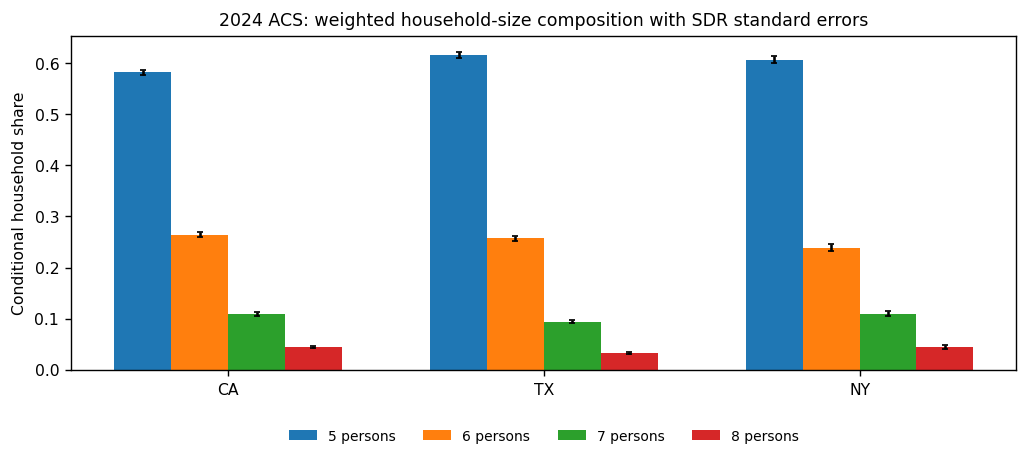

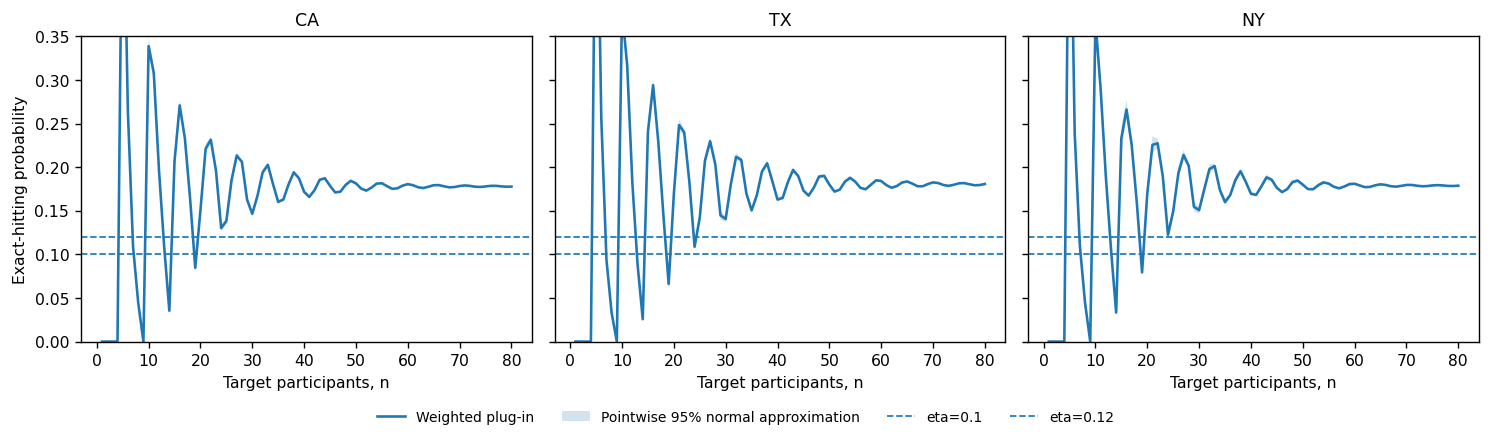

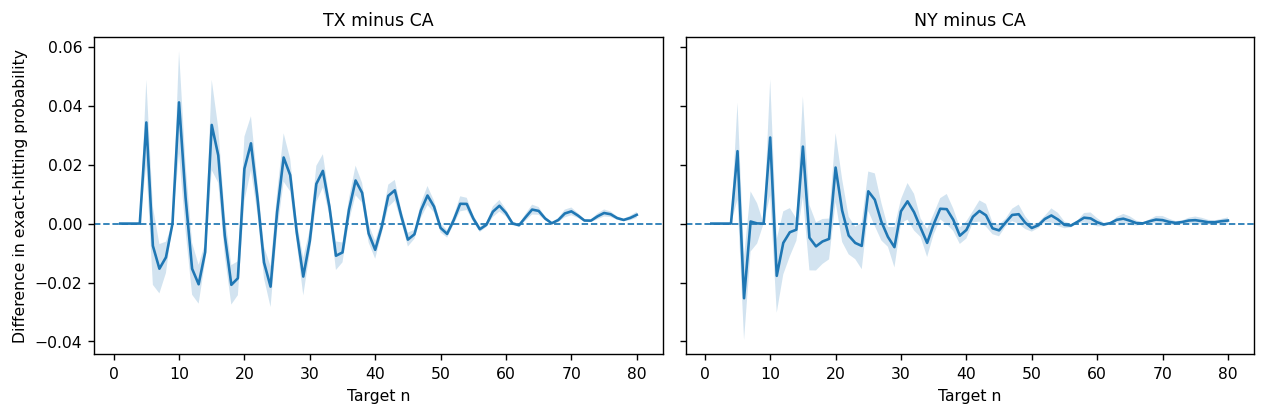

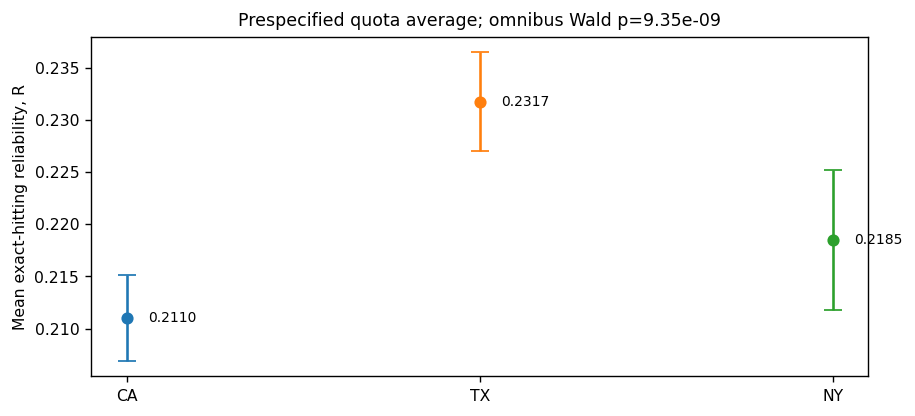

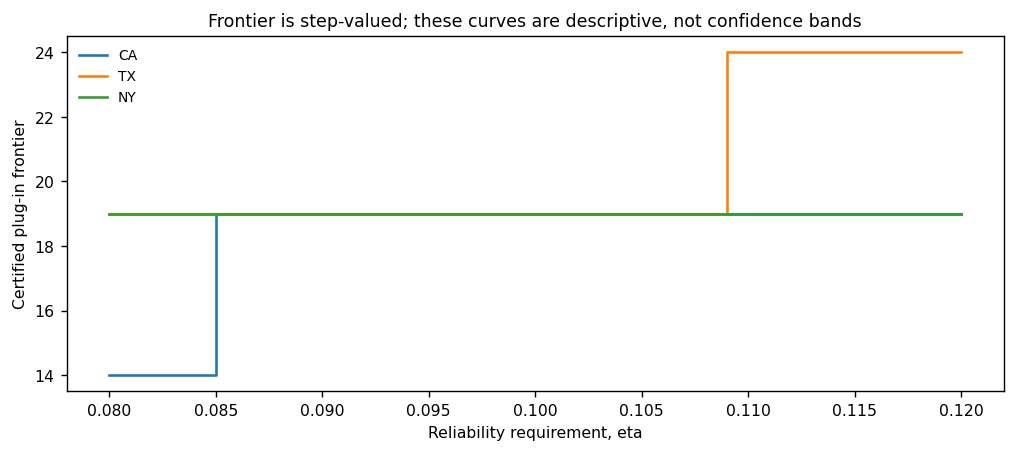

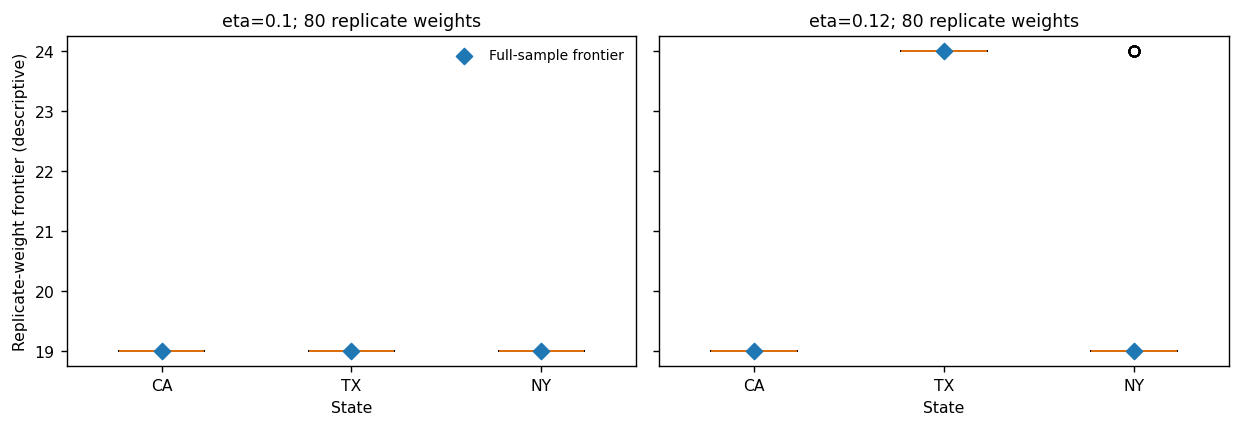

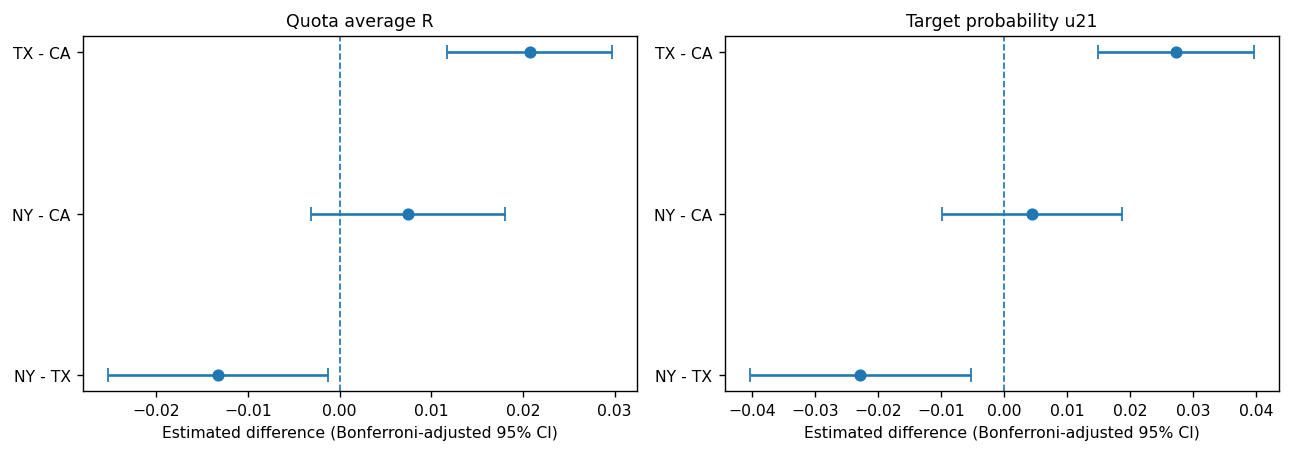


=== PRIMARY REAL-DATA SUMMARY ===
state  eligible_records      p_5      p_6      p_7      p_8        R      u21  F_eta_0.1  F_eta_0.12
   CA             16123 0.582107 0.264535 0.109006 0.044352 0.211022 0.221118         19          19
   TX             10847 0.616415 0.256991 0.093691 0.032903 0.231736 0.248345         19          24
   NY              6557 0.606675 0.239208 0.109709 0.044407 0.218474 0.225553         19          19

=== DESIGN-BASED OMNIBUS TESTS ===
         metric  statistic  df      p_value  variance_condition warning       p_holm
quota_average_R  36.975722   2 9.350264e-09            1.859052         1.870053e-08
     target_u21  33.744442   2 4.704219e-08            1.515685         4.704219e-08

=== PAIRWISE BONFERRONI INTERVALS ===
metric comparison  difference   se_SDR  ci95_lower  ci95_upper                           multiplicity
     R    TX - CA    0.020714 0.003411    0.011715    0.029713 Bonferroni across 6 pairwise contrasts
     R    NY - CA    0.0074

,state,state_name,source,zip_name,zip_sha256,rows_total,eligible_records,excluded_eligible_invalid_weights,nonnumeric_np_rows,estimated_eligible_households,...,R,se_R_SDR,u21,se_u21_SDR,F_eta_0.1,certificate_safe_start_0.1,certificate_safe_end_0.1,F_eta_0.12,certificate_safe_start_0.12,certificate_safe_end_0.12
0,CA,California,https://www2.census.gov/programs-surveys/acs/d...,csv_hca.zip,6228aeac46ebf09cad5c330c18fa761e2ee23390d42bca...,168133,16123,2,0,1730555.0,...,0.211022,0.002106,0.221118,0.002932,19,20,27,19,20,27
1,TX,Texas,https://www2.census.gov/programs-surveys/acs/d...,csv_htx.zip,59274006389de6f8d6ee5f6e2eb48f7f1ccd4d3c9f730d...,132629,10847,1,0,1298923.0,...,0.231736,0.002426,0.248345,0.003462,19,20,27,24,25,32
2,NY,New York,https://www2.census.gov/programs-surveys/acs/d...,csv_hny.zip,36fc963fad086f3ebe37ea05dbe926826d5196ce2c2177...,102908,6557,0,0,678292.0,...,0.218474,0.003403,0.225553,0.004996,19,20,27,19,20,27


,metric,statistic,df,p_value,variance_condition,warning,p_holm
0,quota_average_R,36.975722,2,9.350264e-09,1.859052,,1.870053e-08
1,target_u21,33.744442,2,4.704219e-08,1.515685,,4.704219e-08


,metric,comparison,difference,se_SDR,ci95_lower,ci95_upper,multiplicity
0,R,TX - CA,0.020714,0.003411,0.011715,0.029713,Bonferroni across 6 pairwise contrasts
1,R,NY - CA,0.007452,0.004011,-0.003130,0.018034,Bonferroni across 6 pairwise contrasts
2,R,NY - TX,-0.013262,0.004548,-0.025261,-0.001264,Bonferroni across 6 pairwise contrasts
3,u21,TX - CA,0.027227,0.004687,0.014861,0.039593,Bonferroni across 6 pairwise contrasts
4,u21,NY - CA,0.004435,0.005439,-0.009915,0.018786,Bonferroni across 6 pairwise contrasts
5,u21,NY - TX,-0.022792,0.006651,-0.040338,-0.005246,Bonferroni across 6 pairwise contrasts



READY: /content/stochastic_frobenius_ACS_realdata_v1.zip (1.25 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{'__name__': '__main__',
 '__doc__': '2024 ACS PUMS real-data extension for the stochastic Frobenius paper.\nAPPEND ONLY: standalone; does not modify any earlier numerical study outputs.\nAll reported empirical values are computed from real downloaded ACS household files.\nUS Census Bureau FTP: https://www2.census.gov/programs-surveys/acs/data/pums/2024/1-Year/\nPUMS survey replicate variance: (4/80)*sum_b (estimate_b - estimate_full)^2.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'append_acs_realdata_analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built

In [2]:
import runpy
runpy.run_path('append_acs_realdata_analysis.py', run_name='__main__')